# Objective Quest DATAQUEST 5.0 — V2 Representation-Diversity Ordinal Ensemble

**Goal:** beat the validated V1 baseline (`Public LB = 0.48003`) by adding **new signal representations and genuinely different inductive biases**, not by brute-force hyperparameter tuning.

V1 already transferred almost perfectly from CV to leaderboard, so V2 treats the remaining gap to `0.48853` as a **model/representation ceiling**.

### V2 thesis

- Keep the proven **ordinal regression → continuous score → QWK thresholds** core.
- Use **2 × 5 repeated `StratifiedGroupKFold`** to reduce fold variance.
- Preserve native NaN; no generic median imputation, scaling, SMOTE, or survey-weight sample weighting.
- Fix V1's survey-code weakness with a **dual representation**:
  - raw survey code,
  - dictionary-valid semantic copy,
  - nonstandard-code indicator.
- Add native categorical views for LightGBM/XGBoost instead of treating every nominal code as an ordered number.
- Add one monotonic semantic branch to force a different inductive bias.
- Add multiclass expected-value and cumulative-ordinal sidecars as **objective-diversity candidates**.
- Use nested, fold-safe feature selection. The EDA explainability probe never controls an outer validation fold.
- Select sidecars by **OOF blend delta + residual diversity**, not standalone score alone.
- Fix submission generation permanently: **one prediction per unique `test_final.id` (23,666 rows)**.

### Kaggle runtime
Recommended accelerator: **GPU T4 x2**. CatBoost uses `devices='0:1'`, XGBoost uses CUDA, and LightGBM tries GPU then CPU fallback.

> V2 intentionally trains more models than V1. It is designed as a serious competition experiment, not a minimal baseline.


## 0. Setup & Imports


In [1]:
import os, gc, json, random, warnings, re
from pathlib import Path
from collections import defaultdict

import numpy as np
import pandas as pd
warnings.filterwarnings("ignore")

import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display
from scipy.optimize import minimize
from scipy.stats import ks_2samp

from sklearn.model_selection import StratifiedGroupKFold
from sklearn.metrics import cohen_kappa_score, mean_squared_error, roc_auc_score

import lightgbm as lgb
import xgboost as xgb
from catboost import CatBoostRegressor

try:
    import shap
    HAS_SHAP = True
except Exception as e:
    HAS_SHAP = False
    print("SHAP unavailable; gain importance will still run:", e)


def seed_everything(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    os.environ["PYTHONHASHSEED"] = str(seed)

seed_everything(42)
pd.set_option("display.max_columns", 250)
pd.set_option("display.max_rows", 250)
sns.set_context("notebook")
print("Environment ready")
print("LightGBM:", lgb.__version__)
print("XGBoost:", xgb.__version__)


Environment ready
LightGBM: 4.6.0
XGBoost: 3.2.0


## 1. Problem Understanding & V2 Experiment Contract


In [2]:
class CFG:
    COMPETITION_NAME = "Objective Quest DATAQUEST 5.0"
    VERSION = "v2"

    TRAIN_FILE = "train_final.csv"
    TEST_FILE = "test_final.csv"
    DICT_FILE = "data_dictionary.csv"
    SAMPLE_FILE = "sample_submission.csv"

    TARGET = "life_satisfaction"
    ID_COL = "id"
    HOUSEHOLD_COL = "household_id"

    OUTPUT_DIR = Path("/kaggle/working/oqdq5_v2") if Path("/kaggle/working").exists() else Path("./oqdq5_v2")
    OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

    # Known anchors from V1 / leaderboard.
    V1_PUBLIC_LB = 0.48003
    V1_CROSSFIT_OOF = 0.479662
    CURRENT_TOP1_PUBLIC = 0.48853

    # Repeated grouped CV.
    N_FOLDS = 5
    REPEAT_SEEDS = [42, 2026]
    N_REPEATS = len(REPEAT_SEEDS)

    # EDA-only explainability probe. Never used for final feature selection.
    PROBE_N_ESTIMATORS = 1800
    PROBE_EARLY_STOPPING = 120
    SHAP_SAMPLE = 3000

    # Nested feature selection inside each outer train fold.
    INNER_N_FOLDS = 4
    INNER_TOP_N = 135
    INNER_FS_ESTIMATORS = 1800
    INNER_FS_EARLY_STOPPING = 100

    # Final model budgets.
    LGB_N_ESTIMATORS = 5500
    XGB_N_ESTIMATORS = 5500
    CAT_ITERATIONS = 5500
    LEARNING_RATE = 0.025
    EARLY_STOPPING = 220
    VERBOSE = 400

    USE_GPU = True
    CAT_DEVICES = "0:1"

    # Sidecar branches from V2 analysis.
    RUN_LGB_CATEGORICAL = True
    RUN_XGB_CATEGORICAL = True
    RUN_MONOTONIC = True
    RUN_MULTICLASS = True
    RUN_ORDINAL = True

    # Blend selection: require real OOF gain, not tiny optimizer noise.
    MIN_BRANCH_BLEND_GAIN = 0.00025
    GREEDY_ALPHA_GRID = np.round(np.arange(0.05, 0.56, 0.05), 2)
    MAX_SELECTED_SIDECARS = 4

    # Conservative redundancy repair.
    REPAIR_MIN_ACCURACY = 0.995
    REPAIR_MIN_SUPPORT = 100

    # Submission contract discovered after V1.
    EXPECTED_TEST_ROWS = 23902
    EXPECTED_UNIQUE_TEST_IDS = 23666

    USE_SCALING = False
    USE_OVERSAMPLING = False
    USE_GENERIC_IMPUTATION = False

print({k:v for k,v in vars(CFG).items() if k.isupper()})


{'COMPETITION_NAME': 'Objective Quest DATAQUEST 5.0', 'VERSION': 'v2', 'TRAIN_FILE': 'train_final.csv', 'TEST_FILE': 'test_final.csv', 'DICT_FILE': 'data_dictionary.csv', 'SAMPLE_FILE': 'sample_submission.csv', 'TARGET': 'life_satisfaction', 'ID_COL': 'id', 'HOUSEHOLD_COL': 'household_id', 'OUTPUT_DIR': PosixPath('/kaggle/working/oqdq5_v2'), 'V1_PUBLIC_LB': 0.48003, 'V1_CROSSFIT_OOF': 0.479662, 'CURRENT_TOP1_PUBLIC': 0.48853, 'N_FOLDS': 5, 'REPEAT_SEEDS': [42, 2026], 'N_REPEATS': 2, 'PROBE_N_ESTIMATORS': 1800, 'PROBE_EARLY_STOPPING': 120, 'SHAP_SAMPLE': 3000, 'INNER_N_FOLDS': 4, 'INNER_TOP_N': 135, 'INNER_FS_ESTIMATORS': 1800, 'INNER_FS_EARLY_STOPPING': 100, 'LGB_N_ESTIMATORS': 5500, 'XGB_N_ESTIMATORS': 5500, 'CAT_ITERATIONS': 5500, 'LEARNING_RATE': 0.025, 'EARLY_STOPPING': 220, 'VERBOSE': 400, 'USE_GPU': True, 'CAT_DEVICES': '0:1', 'RUN_LGB_CATEGORICAL': True, 'RUN_XGB_CATEGORICAL': True, 'RUN_MONOTONIC': True, 'RUN_MULTICLASS': True, 'RUN_ORDINAL': True, 'MIN_BRANCH_BLEND_GAIN': 0.00

### Why V2 keeps regression at the core

V1's public score (`0.48003`) landed almost exactly between global and cross-fitted OOF. Therefore the CV framework and QWK calibration are trustworthy. Error analysis showed the biggest contribution to QWK disagreement comes from **class 1 ↔ 2**, not rare class 4. V2 therefore keeps the continuous latent-score core and searches for **better representation of subtle satisfaction differences**.


### 1.1 Auto-discover Kaggle input


In [3]:
def discover_data_dir():
    required = {CFG.TRAIN_FILE, CFG.TEST_FILE, CFG.DICT_FILE, CFG.SAMPLE_FILE}
    roots = [Path("/kaggle/input"), Path("."), Path("./data")]
    candidates = []
    for root in roots:
        if not root.exists():
            continue
        try:
            for p in root.rglob(CFG.TRAIN_FILE):
                folder = p.parent
                present = {x.name for x in folder.iterdir() if x.is_file()}
                if required.issubset(present):
                    candidates.append(folder)
        except PermissionError:
            pass
    if not candidates:
        raise FileNotFoundError(f"Attach a Kaggle dataset containing {sorted(required)}")
    candidates = sorted(set(candidates), key=lambda p: (0 if str(p).startswith('/kaggle/input') else 1, len(str(p))))
    return candidates[0]

DATA_DIR = discover_data_dir()
TRAIN_PATH = DATA_DIR / CFG.TRAIN_FILE
TEST_PATH = DATA_DIR / CFG.TEST_FILE
DICT_PATH = DATA_DIR / CFG.DICT_FILE
SAMPLE_PATH = DATA_DIR / CFG.SAMPLE_FILE
print("DATA_DIR:", DATA_DIR)


DATA_DIR: /kaggle/input/competitions/oq-dq-5


## 2. Preprocessing & Integrity Audit


In [4]:
train = pd.read_csv(TRAIN_PATH, low_memory=False)
test = pd.read_csv(TEST_PATH, low_memory=False)
data_dictionary = pd.read_csv(DICT_PATH)
sample_submission = pd.read_csv(SAMPLE_PATH)

assert CFG.TARGET in train.columns and CFG.TARGET not in test.columns
assert len(train) == 95609, len(train)
assert len(test) == CFG.EXPECTED_TEST_ROWS, len(test)
assert test[CFG.ID_COL].nunique() == CFG.EXPECTED_UNIQUE_TEST_IDS
assert sorted(train[CFG.TARGET].dropna().unique().tolist()) == [1,2,3,4]

print("train:", train.shape)
print("test:", test.shape)
print("unique test ids:", test[CFG.ID_COL].nunique())
print("sample submission rows (known misleading template):", len(sample_submission))


train: (95609, 179)
test: (23902, 178)
unique test ids: 23666
sample submission rows (known misleading template): 23902


### 2.1 Integrity audit and duplicate-safe CV


In [5]:
def integrity_audit(train_df, test_df, sample_df, dictionary_df):
    dict_names = set(dictionary_df["kolom"].astype(str)) if "kolom" in dictionary_df.columns else set()
    return {
        "train_rows": len(train_df),
        "test_rows": len(test_df),
        "train_unique_id": train_df[CFG.ID_COL].nunique(dropna=False),
        "test_unique_id": test_df[CFG.ID_COL].nunique(dropna=False),
        "train_duplicate_id_rows": int(train_df.duplicated(CFG.ID_COL, keep=False).sum()),
        "test_duplicate_id_rows": int(test_df.duplicated(CFG.ID_COL, keep=False).sum()),
        "train_exact_duplicate_rows": int(train_df.duplicated(keep=False).sum()),
        "test_exact_duplicate_rows": int(test_df.duplicated(keep=False).sum()),
        "sample_rows": len(sample_df),
        "sample_id_equals_test_id": bool(CFG.ID_COL in sample_df and np.array_equal(sample_df[CFG.ID_COL].values, test_df[CFG.ID_COL].values)),
        "dictionary_only_columns": sorted(dict_names - set(train_df.columns)),
    }

audit = integrity_audit(train, test, sample_submission, data_dictionary)
display(pd.Series(audit, name="value").to_frame())

# Same-ID train rows must agree on target. CV groups=id prevents exact duplicate leakage.
id_target_nunique = train.groupby(CFG.ID_COL)[CFG.TARGET].nunique(dropna=False)
assert int((id_target_nunique > 1).sum()) == 0

# Duplicate test IDs must truly represent identical raw rows before we aggregate predictions.
for _, g in test[test.duplicated(CFG.ID_COL, keep=False)].groupby(CFG.ID_COL):
    assert len(g.drop_duplicates()) == 1

print("Integrity checks passed. Evaluator contract = one row per unique test_final.id.")


,value
train_rows,95609
test_rows,23902
train_unique_id,94663
test_unique_id,23666
train_duplicate_id_rows,1892
test_duplicate_id_rows,472
train_exact_duplicate_rows,1892
test_exact_duplicate_rows,472
sample_rows,23902
sample_id_equals_test_id,False


Integrity checks passed. Evaluator contract = one row per unique test_final.id.


### 2.2 Repeated grouped folds


In [6]:
y = train[CFG.TARGET].astype(int).values
groups = train[CFG.ID_COL].astype(str).values
survey_year_for_strata = train["survey_year"].fillna(-1).astype(str) if "survey_year" in train.columns else pd.Series("NA", index=train.index)
strata = train[CFG.TARGET].astype(str) + "__yr_" + survey_year_for_strata

repeated_folds = []
fold_audit_rows = []
for repeat, seed in enumerate(CFG.REPEAT_SEEDS):
    cv = StratifiedGroupKFold(n_splits=CFG.N_FOLDS, shuffle=True, random_state=seed)
    folds = list(cv.split(train, strata, groups=groups))
    for fold, (tr_idx, va_idx) in enumerate(folds):
        overlap = set(groups[tr_idx]).intersection(set(groups[va_idx]))
        assert not overlap
        repeated_folds.append((repeat, fold, seed, tr_idx, va_idx))
        fold_audit_rows.append({
            "repeat": repeat, "fold": fold, "seed": seed,
            "train_n": len(tr_idx), "valid_n": len(va_idx),
            "group_overlap": len(overlap),
            "valid_target_mean": float(y[va_idx].mean()),
        })

display(pd.DataFrame(fold_audit_rows))


,repeat,fold,seed,train_n,valid_n,group_overlap,valid_target_mean
0,0,0,42,76485,19124,0,1.606672
1,0,1,42,76500,19109,0,1.605893
2,0,2,42,76487,19122,0,1.611024
3,0,3,42,76491,19118,0,1.604090
4,0,4,42,76473,19136,0,1.604776
5,1,0,2026,76501,19108,0,1.604459
6,1,1,2026,76477,19132,0,1.605373
7,1,2,2026,76476,19133,0,1.610255
8,1,3,2026,76483,19126,0,1.611994
9,1,4,2026,76499,19110,0,1.600366


### 2.3 Fold-safe redundancy-aware repair


In [7]:
REPAIR_PAIRS = [
    ("data_year", "survey_year"),
    ("survey_year", "data_year"),
    ("interview_month", "interview_quarter"),
    ("food_security_4cat", "food_security_3cat"),
    ("cancer_types_count", "cancer_ever"),
    ("ecigarette_status", "ever_used_ecigarette"),
    ("children_in_family", "children_in_household"),
    ("children_in_household", "children_in_family"),
    ("smoking_status", "ever_smoked"),
    ("health_insurance_type", "private_health_insurance"),
    ("marital_status_detailed", "marital_status"),
]

SPECIAL_CODES = {
    "weight_pounds": {996, 997, 999},
    "height_inches": {96, 97, 98, 99},
    "age": {97, 99},
    "hours_worked_per_week": {990},
    "days_missed_work": {997, 998, 999},
    "income_to_poverty_ratio": {110},
}


def learn_mode_mapping(df, src, dst, min_support=100):
    if src not in df.columns or dst not in df.columns:
        return None
    pairs = df[[src, dst]].dropna()
    if len(pairs) < min_support:
        return None
    mapping = pairs.groupby(src)[dst].agg(lambda s: s.mode().iloc[0] if not s.mode().empty else np.nan).to_dict()
    pred = pairs[src].map(mapping)
    return {"mapping": mapping, "accuracy": float((pred.values == pairs[dst].values).mean()), "support": len(pairs)}


class FoldPreprocessor:
    def __init__(self, min_accuracy=0.995, min_support=100):
        self.min_accuracy = min_accuracy
        self.min_support = min_support
        self.repair_rules_ = {}
        self.repair_report_ = None

    def fit(self, df):
        rows=[]
        for src,dst in REPAIR_PAIRS:
            learned = learn_mode_mapping(df, src, dst, self.min_support)
            if learned is None:
                continue
            accepted = learned["accuracy"] >= self.min_accuracy
            rows.append({"source":src,"destination":dst,"accuracy":learned["accuracy"],"support":learned["support"],"accepted":accepted})
            if accepted:
                self.repair_rules_[(src,dst)] = learned["mapping"]
        self.repair_report_ = pd.DataFrame(rows)
        return self

    def transform(self, df):
        out = df.drop(columns=[CFG.TARGET], errors="ignore").copy()
        base_cols = [c for c in out.columns if c not in [CFG.ID_COL, CFG.HOUSEHOLD_COL]]
        out["row_missing_count_raw"] = out[base_cols].isna().sum(axis=1).astype(np.int16)

        before_missing = out[base_cols].isna().sum(axis=1)
        for (src,dst),mapping in self.repair_rules_.items():
            if src not in out or dst not in out:
                continue
            mask = out[dst].isna() & out[src].notna()
            if mask.any():
                inferred = out.loc[mask,src].map(mapping)
                idx = inferred[inferred.notna()].index
                out.loc[idx,dst] = inferred.loc[idx]
        after_missing = out[base_cols].isna().sum(axis=1)
        out["row_missing_count_after_repair"] = after_missing.astype(np.int16)
        out["repaired_value_count"] = (before_missing-after_missing).astype(np.int16)

        special_cols=[]
        for col,codes in SPECIAL_CODES.items():
            if col in out.columns:
                flag = f"{col}__special_code"
                out[flag] = out[col].isin(codes).astype(np.int8)
                special_cols.append(flag)
        out["special_code_count"] = out[special_cols].sum(axis=1).astype(np.int16) if special_cols else 0
        return out


### 2.4 V2 semantic survey-code representation

V1 retained codes such as `7/8/9` as ordinary numbers in many coded variables. V2 parses **explicit valid codes from `data_dictionary.csv`** and creates:

- `feature` — raw code, unchanged;
- `feature__semantic` — only dictionary-valid codes, nonstandard codes become `NaN`;
- `feature__nonstandard` — indicator that the observed code is outside the documented valid set.

This is deliberately additive: V2 never silently destroys the raw code.


In [8]:
def parse_valid_codes(value_text):
    if pd.isna(value_text):
        return None
    s = str(value_text).strip()
    if not s or s.lower() in {"numerik", "nilai tahun", "kode numerik"}:
        return None

    # Explicit mappings: 1=..., 2=..., ...
    matches = re.findall(r"(?:^|,)\s*(-?\d+(?:\.\d+)?)\s*=", s)
    if matches:
        vals = sorted({float(x) for x in matches})
        return vals if 1 <= len(vals) <= 30 else None

    # Simple integer range, e.g. 1-12 or 18-85. Keep only compact coded ranges.
    m = re.fullmatch(r"\s*(-?\d+)\s*-\s*(-?\d+)\+?\s*", s)
    if m:
        lo,hi = map(int,m.groups())
        if 0 <= hi-lo <= 30:
            return [float(x) for x in range(lo,hi+1)]
        return None

    # Bare comma-separated numeric list (e.g. survey years).
    parts = [p.strip() for p in s.split(',')]
    if 1 < len(parts) <= 30:
        try:
            return sorted({float(p) for p in parts})
        except Exception:
            return None
    return None


def build_dictionary_valid_code_map(dictionary_df, feature_names):
    result={}
    if not {"kolom","nilai"}.issubset(dictionary_df.columns):
        return result
    for _,row in dictionary_df.iterrows():
        col=str(row["kolom"])
        if col not in feature_names:
            continue
        vals=parse_valid_codes(row["nilai"])
        if vals is not None:
            result[col]=set(vals)
    return result

DICT_VALID_CODES = build_dictionary_valid_code_map(data_dictionary, set(test.columns))
print("Dictionary-coded columns parsed:", len(DICT_VALID_CODES))

# Only create semantic copies where nonstandard observed values actually exist.
combined_for_audit = pd.concat([train.drop(columns=[CFG.TARGET]), test], axis=0, ignore_index=True)
SEMANTIC_CODE_COLS=[]
semantic_audit=[]
for col,valid in DICT_VALID_CODES.items():
    if col not in combined_for_audit:
        continue
    numeric = pd.to_numeric(combined_for_audit[col], errors="coerce")
    nonstd = numeric.notna() & ~numeric.isin(valid)
    if nonstd.any():
        SEMANTIC_CODE_COLS.append(col)
        semantic_audit.append({
            "feature":col,
            "valid_codes":sorted(valid),
            "nonstandard_rows":int(nonstd.sum()),
            "nonstandard_rate":float(nonstd.mean()),
            "observed_nonstandard":sorted(numeric[nonstd].dropna().unique().tolist())[:20],
        })

semantic_audit_df = pd.DataFrame(semantic_audit).sort_values("nonstandard_rate", ascending=False)
print("Columns receiving dual semantic representation:", len(SEMANTIC_CODE_COLS))
display(semantic_audit_df.head(40))


Dictionary-coded columns parsed: 161
Columns receiving dual semantic representation: 150


,feature,valid_codes,nonstandard_rows,nonstandard_rate,observed_nonstandard
68,child_government_insurance,"[1.0, 2.0]",110110,0.921338,"[3.0, 7.0, 9.0]"
70,other_government_insurance,"[1.0, 2.0]",109750,0.918326,"[3.0, 7.0, 9.0]"
69,state_health_plan,"[1.0, 2.0]",109308,0.914627,"[3.0, 7.0, 9.0]"
71,military_health_insurance,"[1.0, 2.0]",103164,0.863218,"[3.0, 7.0, 9.0]"
52,low_income_government_insurance,"[1.0, 2.0]",96387,0.806512,"[3.0, 7.0, 9.0]"
141,income_poverty_category,"[1.0, 2.0, 3.0, 4.0]",94434,0.790170,"[5.0, 6.0, 7.0, 8.0, 9.0, 10.0, 11.0, 12.0, 13..."
123,legal_marital_status,"[1.0, 2.0]",91685,0.767168,"[3.0, 4.0, 5.0, 9.0]"
124,parental_status,"[1.0, 2.0]",82382,0.689326,"[3.0, 9.0]"
5,max_education_in_family,"[1.0, 2.0, 3.0, 4.0]",82222,0.687987,"[5.0, 6.0, 7.0, 8.0, 9.0, 10.0]"
3,education_level,"[1.0, 2.0, 3.0, 4.0]",73348,0.613734,"[5.0, 6.0, 7.0, 8.0, 9.0, 10.0, 97.0, 99.0, 99..."


## 3. Fitting for Explainable AI (EDA-only probe)


In [9]:
def qwk(y_true, y_pred_class):
    return cohen_kappa_score(np.asarray(y_true), np.asarray(y_pred_class), weights="quadratic")


def apply_thresholds(pred, thresholds):
    t=np.sort(np.asarray(thresholds,dtype=float))
    return np.digitize(np.asarray(pred), bins=t).astype(int)+1


def initial_thresholds_from_distribution(y_true, continuous_pred):
    counts=pd.Series(y_true).value_counts(normalize=True).sort_index()
    cum=np.cumsum([counts.get(k,0.0) for k in [1,2,3]])
    return np.quantile(continuous_pred, np.clip(cum,0.001,0.999))


def optimize_thresholds(y_true, continuous_pred, starts=None, maxiter=160):
    y_true=np.asarray(y_true)
    p=np.asarray(continuous_pred,dtype=float)
    if starts is None:
        starts=[initial_thresholds_from_distribution(y_true,p), np.array([1.55,2.03,2.52])]
    best=None
    for start in starts:
        start=np.sort(np.asarray(start,dtype=float))
        def objective(t):
            ts=np.sort(t)
            if np.min(np.diff(ts)) < 0.03:
                return 1e3
            return -qwk(y_true, apply_thresholds(p,ts))
        res=minimize(objective,start,method="Nelder-Mead",options={"maxiter":maxiter,"xatol":1e-5,"fatol":1e-7})
        ts=np.sort(res.x)
        score=qwk(y_true,apply_thresholds(p,ts))
        if best is None or score>best[1]:
            best=(ts,score)
    return best


def make_basic_engineered_for_probe(raw_df):
    pre=FoldPreprocessor(CFG.REPAIR_MIN_ACCURACY,CFG.REPAIR_MIN_SUPPORT).fit(raw_df)
    return pre.transform(raw_df)

# Probe uses a held-out grouped split only for understanding / EDA. It NEVER determines final outer-fold features.
probe_cv=StratifiedGroupKFold(n_splits=5,shuffle=True,random_state=777)
probe_tr_idx,probe_va_idx=next(probe_cv.split(train,strata,groups=groups))
probe_pre=FoldPreprocessor(CFG.REPAIR_MIN_ACCURACY,CFG.REPAIR_MIN_SUPPORT).fit(train.iloc[probe_tr_idx])
X_probe_tr=probe_pre.transform(train.iloc[probe_tr_idx])
X_probe_va=probe_pre.transform(train.iloc[probe_va_idx])

probe_features=[c for c in X_probe_tr.columns if c not in [CFG.ID_COL,CFG.HOUSEHOLD_COL]]
probe=lgb.LGBMRegressor(
    objective="regression_l2",n_estimators=CFG.PROBE_N_ESTIMATORS,learning_rate=0.03,
    num_leaves=31,min_child_samples=40,colsample_bytree=0.85,subsample=0.85,subsample_freq=1,
    reg_lambda=4.0,random_state=777,n_jobs=-1,verbosity=-1,
)
probe.fit(X_probe_tr[probe_features],y[probe_tr_idx],eval_set=[(X_probe_va[probe_features],y[probe_va_idx])],
          callbacks=[lgb.early_stopping(CFG.PROBE_EARLY_STOPPING,verbose=False)])
probe_pred=probe.predict(X_probe_va[probe_features],num_iteration=probe.best_iteration_)
probe_t,probe_qwk=optimize_thresholds(y[probe_va_idx],probe_pred)
print("EDA-only probe QWK:", round(probe_qwk,6), "thresholds:", np.round(probe_t,5))

probe_importance=pd.DataFrame({"feature":probe_features,"gain":probe.booster_.feature_importance(importance_type="gain")}).sort_values("gain",ascending=False)
probe_importance["gain_norm"]=probe_importance["gain"]/max(probe_importance["gain"].sum(),1e-12)
display(probe_importance.head(30))

if HAS_SHAP:
    sample_idx=np.random.default_rng(42).choice(len(X_probe_va),size=min(CFG.SHAP_SAMPLE,len(X_probe_va)),replace=False)
    explainer=shap.TreeExplainer(probe)
    sv=explainer.shap_values(X_probe_va.iloc[sample_idx][probe_features])
    shap_imp=pd.DataFrame({"feature":probe_features,"mean_abs_shap":np.abs(np.asarray(sv)).mean(axis=0)}).sort_values("mean_abs_shap",ascending=False)
    display(shap_imp.head(30))


EDA-only probe QWK: 0.480638 thresholds: [1.54167 2.02251 2.44342]


,feature,gain,gain_norm
66,depression_frequency,41346.881955,0.291088
143,general_health_status,36025.915717,0.253627
72,anxiety_frequency,6496.541354,0.045737
98,marital_status,5765.101996,0.040587
5,difficulty_social_activities,4212.039727,0.029653
92,marital_status_detailed,3044.504670,0.021434
54,worry_about_medical_costs,2959.910293,0.020838
3,income_to_poverty_ratio,2678.460127,0.018857
130,difficulty_remembering,2021.751212,0.014233
158,anxiety_level,1769.972799,0.012461


,feature,mean_abs_shap
143,general_health_status,0.124050
66,depression_frequency,0.092669
98,marital_status,0.039683
72,anxiety_frequency,0.039302
54,worry_about_medical_costs,0.028988
92,marital_status_detailed,0.019358
5,difficulty_social_activities,0.017400
3,income_to_poverty_ratio,0.016994
174,sex,0.016746
158,anxiety_level,0.016573


## 4. EDA — Hidden Gems, Missingness, Relationships, and V1 Error Priorities


### 4.1 Target distribution and V1 leaderboard anchor


,count,share
life_satisfaction,,
1,42968,0.449414
2,48189,0.504022
3,3559,0.037225
4,893,0.009340


V1 Public LB: 0.48003
V1 Cross-fitted OOF: 0.479662
Gap to current Top 1: 0.0085


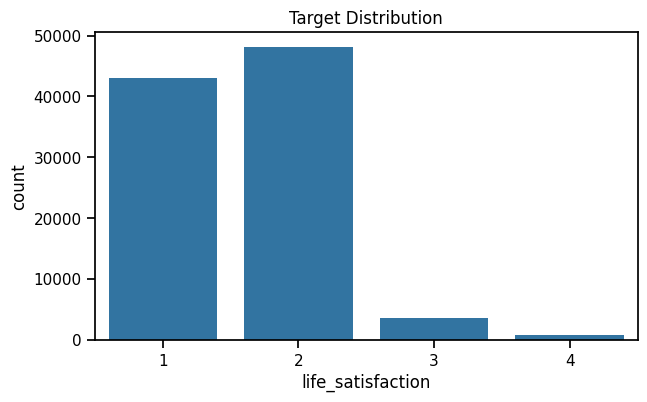

In [10]:
target_counts=train[CFG.TARGET].value_counts().sort_index()
target_dist=(target_counts/len(train)).rename("share")
display(pd.concat([target_counts.rename("count"),target_dist],axis=1))
print("V1 Public LB:",CFG.V1_PUBLIC_LB)
print("V1 Cross-fitted OOF:",CFG.V1_CROSSFIT_OOF)
print("Gap to current Top 1:",round(CFG.CURRENT_TOP1_PUBLIC-CFG.V1_PUBLIC_LB,5))

plt.figure(figsize=(7,4))
sns.countplot(data=train,x=CFG.TARGET)
plt.title("Target Distribution")
plt.show()


### 4.2 Missingness remains a feature


In [11]:
raw_feature_cols=[c for c in test.columns if c not in [CFG.ID_COL,CFG.HOUSEHOLD_COL]]
row_missing=train[raw_feature_cols].isna().sum(axis=1)
missing_target=pd.DataFrame({"missing_count":row_missing,"target":train[CFG.TARGET]})
missing_target["missing_bin"]=pd.qcut(missing_target["missing_count"],q=10,duplicates="drop")
display(missing_target.groupby("missing_bin",observed=True).agg(n=("target","size"),mean_target=("target","mean"),mean_missing=("missing_count","mean")))

miss=pd.DataFrame({
    "train_missing":train[raw_feature_cols].isna().mean(),
    "test_missing":test[raw_feature_cols].isna().mean(),
})
miss["abs_diff"]=(miss.train_missing-miss.test_missing).abs()
display(miss.sort_values("train_missing",ascending=False).head(35))


,n,mean_target,mean_missing
missing_bin,,,
"(3.999, 15.0]",12158,1.567034,13.147722
"(15.0, 17.0]",8663,1.542884,16.522683
"(17.0, 19.0]",9668,1.532065,18.505482
"(19.0, 21.0]",9191,1.538135,20.487977
"(21.0, 24.0]",10703,1.542932,22.906568
"(24.0, 27.0]",7398,1.603001,25.916058
"(27.0, 31.0]",9753,1.655183,29.588742
"(31.0, 34.0]",9417,1.685462,33.028565
"(34.0, 38.0]",11229,1.698816,36.379998


,train_missing,test_missing,abs_diff
flu_vaccine_year,0.538485,0.542800,0.004315
flu_vaccine_month,0.534291,0.540833,0.006543
ever_married,0.521112,0.520919,0.000193
gestational_diabetes_ever,0.500152,0.492051,0.008101
works_full_time,0.485854,0.485692,0.000162
hours_worked_per_week,0.485080,0.484102,0.000978
insurance_marketplace_plan1,0.449884,0.452180,0.002295
days_missed_work,0.440147,0.437871,0.002276
has_paid_sick_leave,0.439645,0.439628,0.000016
employer_offers_insurance,0.439341,0.435361,0.003980


### 4.3 Semantic outliers / undocumented survey codes


In [12]:
display(semantic_audit_df.head(50))

# V1 continuous sentinel audit retained for physical/continuous fields.
rows=[]
for col,codes in SPECIAL_CODES.items():
    if col in train:
        for val in sorted(codes):
            mask=train[col].eq(val)
            rows.append({"feature":col,"code":val,"train_n":int(mask.sum()),"target_mean":float(train.loc[mask,CFG.TARGET].mean()) if mask.any() else np.nan,"test_n":int(test[col].eq(val).sum())})
display(pd.DataFrame(rows))


,feature,valid_codes,nonstandard_rows,nonstandard_rate,observed_nonstandard
68,child_government_insurance,"[1.0, 2.0]",110110,0.921338,"[3.0, 7.0, 9.0]"
70,other_government_insurance,"[1.0, 2.0]",109750,0.918326,"[3.0, 7.0, 9.0]"
69,state_health_plan,"[1.0, 2.0]",109308,0.914627,"[3.0, 7.0, 9.0]"
71,military_health_insurance,"[1.0, 2.0]",103164,0.863218,"[3.0, 7.0, 9.0]"
52,low_income_government_insurance,"[1.0, 2.0]",96387,0.806512,"[3.0, 7.0, 9.0]"
141,income_poverty_category,"[1.0, 2.0, 3.0, 4.0]",94434,0.790170,"[5.0, 6.0, 7.0, 8.0, 9.0, 10.0, 11.0, 12.0, 13..."
123,legal_marital_status,"[1.0, 2.0]",91685,0.767168,"[3.0, 4.0, 5.0, 9.0]"
124,parental_status,"[1.0, 2.0]",82382,0.689326,"[3.0, 9.0]"
5,max_education_in_family,"[1.0, 2.0, 3.0, 4.0]",82222,0.687987,"[5.0, 6.0, 7.0, 8.0, 9.0, 10.0]"
3,education_level,"[1.0, 2.0, 3.0, 4.0]",73348,0.613734,"[5.0, 6.0, 7.0, 8.0, 9.0, 10.0, 97.0, 99.0, 99..."


,feature,code,train_n,target_mean,test_n
0,weight_pounds,996,5836,1.738177,1446
1,weight_pounds,997,919,1.576714,230
2,weight_pounds,999,729,1.722908,158
3,height_inches,96,5829,1.739578,1441
4,height_inches,97,88,1.511364,20
5,height_inches,98,47,1.638298,7
6,height_inches,99,202,1.712871,52
7,age,97,168,1.541667,43
8,age,99,18,1.722222,4
9,hours_worked_per_week,990,482,1.582988,133


### 4.4 Train-test drift sanity check


In [13]:
def total_variation_distance(a,b):
    av=a.value_counts(normalize=True,dropna=False)
    bv=b.value_counts(normalize=True,dropna=False)
    idx=av.index.union(bv.index)
    return 0.5*np.abs(av.reindex(idx,fill_value=0)-bv.reindex(idx,fill_value=0)).sum()

drift_rows=[]
for c in raw_feature_cols:
    a=train[c]; b=test[c]
    nunique=max(a.nunique(dropna=True),b.nunique(dropna=True))
    if nunique<=30:
        drift=total_variation_distance(a,b)
        kind="TV"
    else:
        aa=pd.to_numeric(a,errors="coerce").dropna(); bb=pd.to_numeric(b,errors="coerce").dropna()
        drift=ks_2samp(aa,bb).statistic if len(aa) and len(bb) else np.nan
        kind="KS"
    drift_rows.append({"feature":c,"metric":kind,"drift":drift})
drift_df=pd.DataFrame(drift_rows).sort_values("drift",ascending=False)
display(drift_df.head(35))


,feature,metric,drift
18,income_poverty_category,TV,0.012106
78,height_inches,TV,0.011981
12,flu_vaccine_month,TV,0.010875
32,delayed_prescription_to_save_money,TV,0.010048
54,worry_about_medical_costs,TV,0.009993
38,gestational_diabetes_ever,TV,0.009889
162,years_in_current_home,TV,0.009847
154,skipped_medication_to_save_money,TV,0.009828
47,depression_ever,TV,0.009814
73,took_prescription_medication,TV,0.009431


### 4.5 Correlation heatmap on strongest probe features


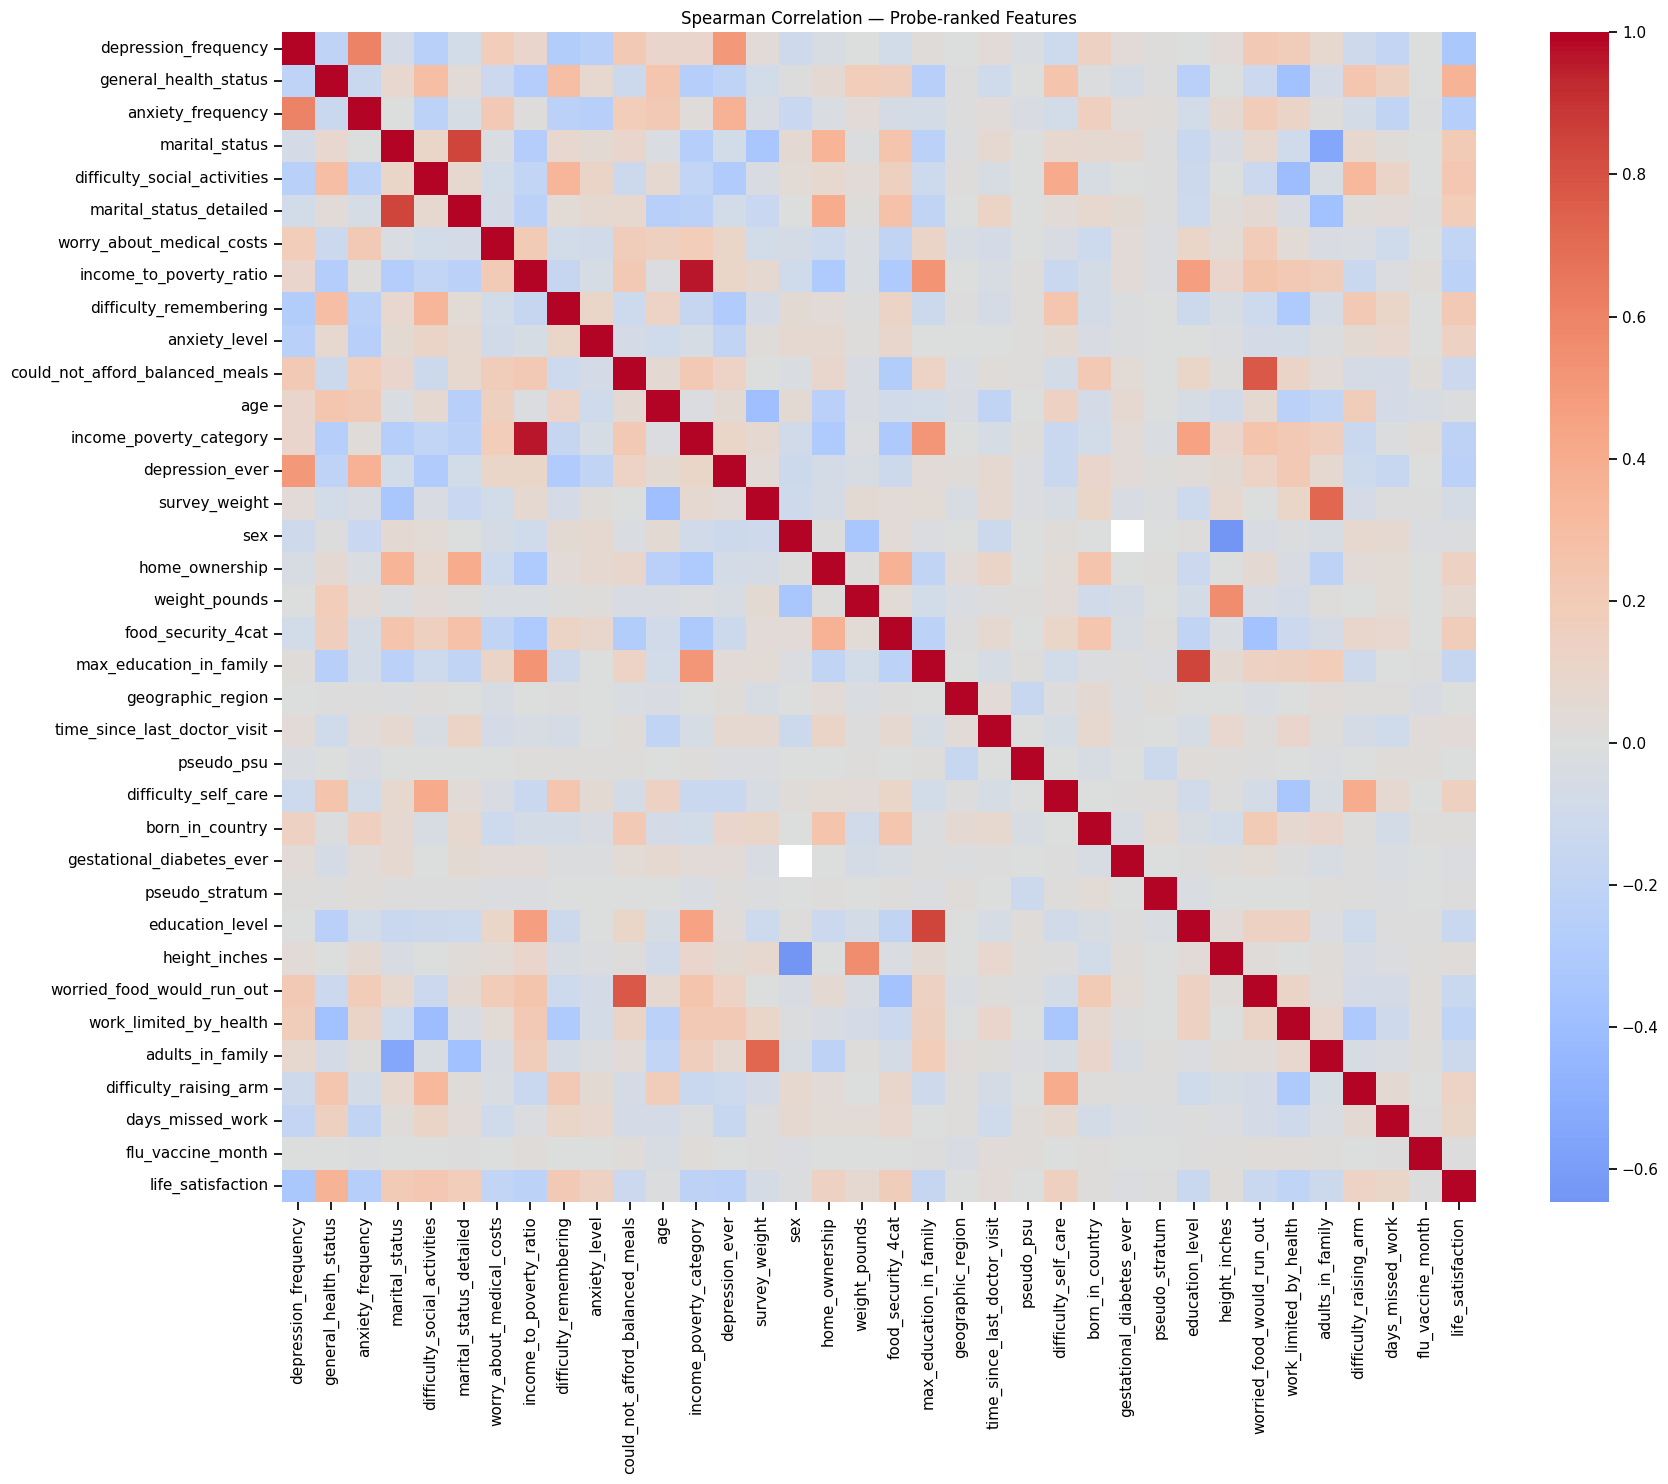

In [14]:
top_numeric=[c for c in probe_importance.feature.head(35) if c in train.columns]
corr_frame=train[top_numeric+[CFG.TARGET]].apply(pd.to_numeric,errors="coerce")
plt.figure(figsize=(18,15))
sns.heatmap(corr_frame.corr(method="spearman"),cmap="coolwarm",center=0)
plt.title("Spearman Correlation — Probe-ranked Features")
plt.tight_layout(); plt.show()


### 4.6 High-value interaction heatmaps


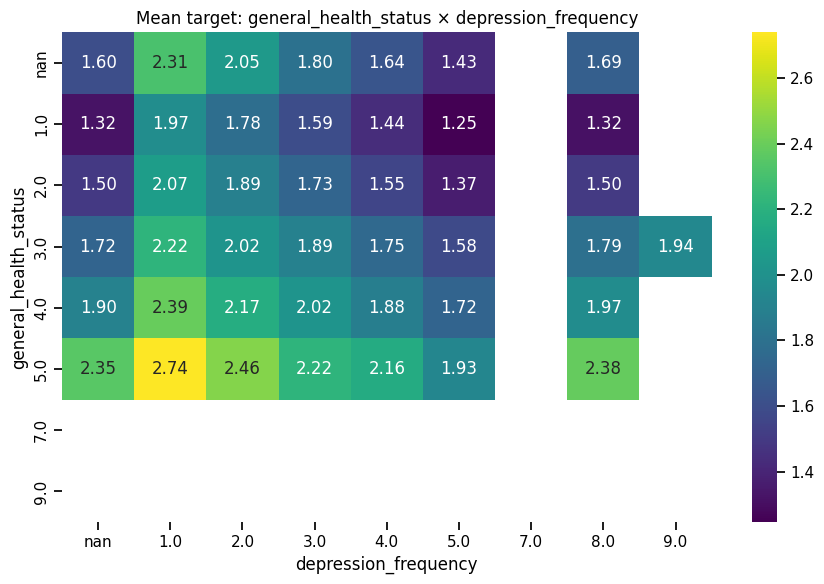

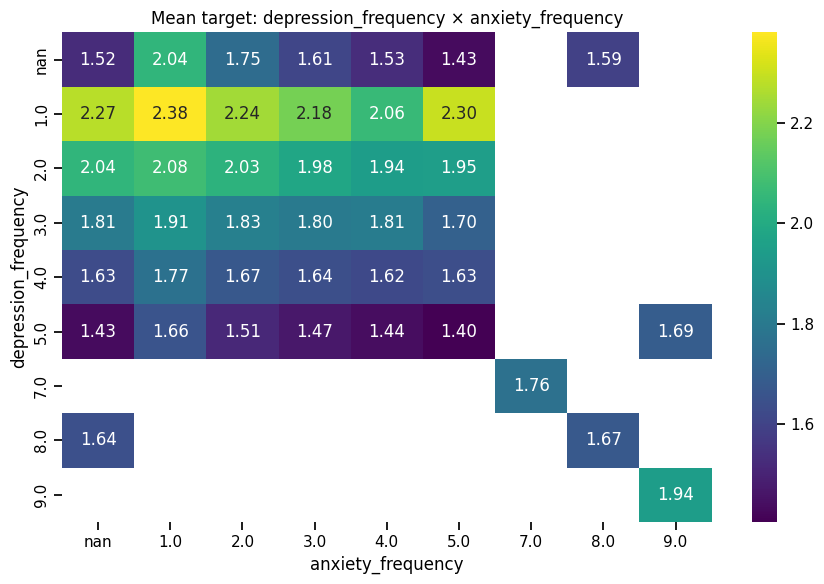

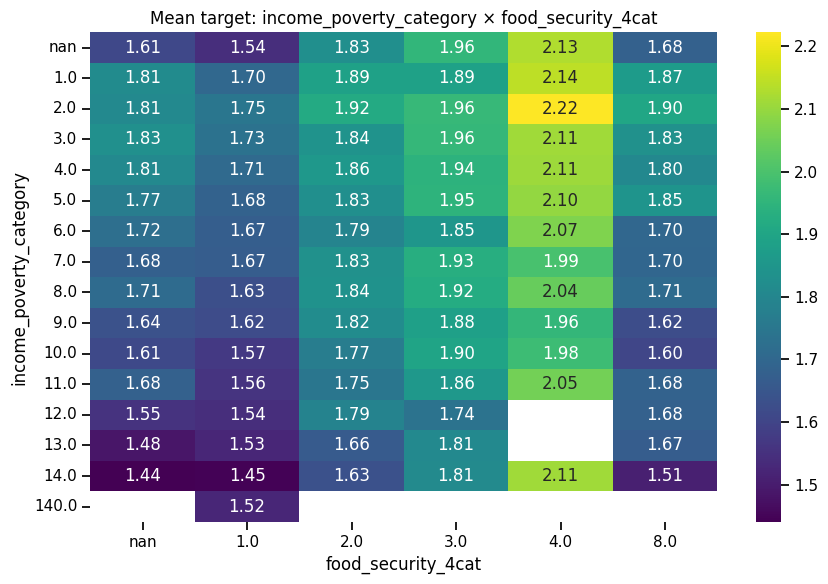

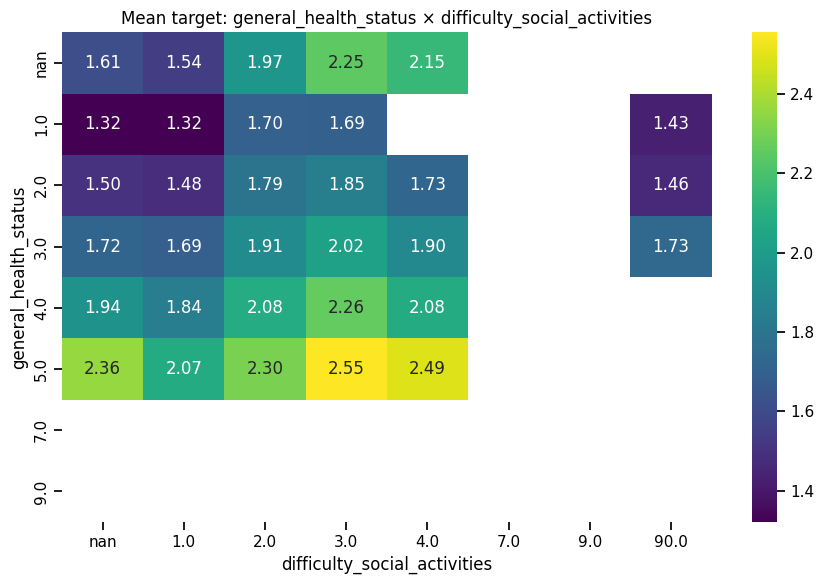

In [15]:
def interaction_heatmap(df,row_feature,col_feature,min_count=50):
    if row_feature not in df or col_feature not in df:
        return
    g=df.groupby([row_feature,col_feature],dropna=False)[CFG.TARGET].agg(["mean","count"]).reset_index()
    g.loc[g["count"]<min_count,"mean"]=np.nan
    pivot=g.pivot(index=row_feature,columns=col_feature,values="mean")
    plt.figure(figsize=(9,6)); sns.heatmap(pivot,annot=True,fmt=".2f",cmap="viridis")
    plt.title(f"Mean target: {row_feature} × {col_feature}"); plt.tight_layout(); plt.show()

for a,b in [
    ("general_health_status","depression_frequency"),
    ("depression_frequency","anxiety_frequency"),
    ("income_poverty_category","food_security_4cat"),
    ("general_health_status","difficulty_social_activities"),
]:
    interaction_heatmap(train,a,b)


## 5. Feature Engineering


### V2 feature-engineering policy by requested category

- **Discretization:** only conservative `age_band`; trees keep the raw continuous values too.
- **Feature Selection:** nested grouped inner split inside every outer fold; no outer-validation feature-selection leakage.
- **Feature Creation:** domain burden counts, missingness/repair counts, semantic-code indicators, and a very small interaction bank.
- **Clipping / outliers:** no blind winsorization or row dropping. Survey sentinel/nonstandard values are represented semantically while the raw code is preserved.
- **Feature Encoding:** raw numeric view + dictionary-valid semantic view + native categorical copies for selected nominal fields.

This follows the V1 finding that adding more arbitrary features does not automatically improve QWK.

In [16]:
FUNCTIONAL_DIFFICULTY_COLS = [
    "difficulty_walking_steps","difficulty_walking_short","difficulty_walking_medium","difficulty_climbing_steps",
    "difficulty_using_hands","difficulty_raising_arm","difficulty_self_care","difficulty_communicating",
    "difficulty_remembering","difficulty_errands_alone","difficulty_social_activities",
]
CHRONIC_CONDITION_COLS = [
    "hypertension_ever","high_cholesterol_ever","heart_disease_ever","heart_attack_ever","angina_ever","stroke_ever",
    "asthma_ever","diabetes_ever","prediabetes_ever","cancer_ever","lung_disease_ever","arthritis_ever","dementia_ever","chronic_fatigue_ever",
]
COST_BARRIER_YES_COLS = [
    "trouble_paying_medical_bills","delayed_care_due_to_cost","skipped_care_due_to_cost",
    "skipped_medication_to_save_money","took_less_medication_to_save_money","delayed_prescription_to_save_money",
    "skipped_prescription_due_to_cost","delayed_therapy_due_to_cost","skipped_therapy_due_to_cost",
]
INCOME_SOURCE_COLS = ["has_wage_income","has_investment_income","has_social_security_income","has_disability_income","has_public_assistance_income","has_retirement_income","has_other_income"]
INSURANCE_YES_COLS = ["has_health_insurance","has_private_insurance","has_senior_gov_insurance","has_lowincome_gov_insurance","has_child_gov_insurance","has_military_insurance","has_state_health_plan","has_other_gov_insurance"]
FREQUENCY_COLS=[CFG.HOUSEHOLD_COL,"pseudo_stratum","pseudo_psu"]

# Conservative nominal list: these are not treated as ordinal just because their source codes are integers.
NATIVE_NOMINAL_COLS = [
    "record_type","survey_year","geographic_region","pseudo_stratum","pseudo_psu","sex","citizenship_status","born_in_country",
    "sexual_orientation","parental_status","relationship_to_child","marital_status","legal_marital_status","marital_status_detailed",
    "health_insurance_type","insurance_source_plan1","type_of_care_provider","home_ownership","smoking_status","ecigarette_status",
    "interview_quarter","interview_month",
]


def count_yes(df,cols):
    cols=[c for c in cols if c in df]
    return (df[cols]==1).sum(axis=1).astype(np.int16) if cols else pd.Series(0,index=df.index,dtype=np.int16)


def reverse_ordinal(series,max_valid):
    s=pd.to_numeric(series,errors="coerce")
    out=pd.Series(np.nan,index=s.index,dtype=float)
    valid=s.between(1,max_valid)
    out.loc[valid]=(max_valid+1)-s.loc[valid]
    return out


class SemanticFeatureEngineer:
    def __init__(self, valid_code_map):
        self.valid_code_map=valid_code_map
        self.frequency_maps_={}
        self.engineered_feature_names_=[]
        self.semantic_cols_=[]

    def fit(self,df):
        for c in FREQUENCY_COLS:
            if c in df:
                self.frequency_maps_[c]=df[c].value_counts(dropna=False).to_dict()
        return self

    def transform(self,df):
        out=df.copy(); before=set(out.columns)

        # Fold-safe frequency encoding only; household raw ID is later dropped.
        for c,mapping in self.frequency_maps_.items():
            if c in out:
                out[f"{c}__frequency"]=out[c].map(mapping).fillna(0).astype(np.float32)
                out[f"{c}__log_frequency"]=np.log1p(out[f"{c}__frequency"]).astype(np.float32)

        # V2 dual semantic representation for undocumented survey codes.
        semantic_cols=[]; nonstd_cols=[]
        for c in SEMANTIC_CODE_COLS:
            if c not in out or c not in self.valid_code_map:
                continue
            raw=pd.to_numeric(out[c],errors="coerce")
            valid=self.valid_code_map[c]
            sem_name=f"{c}__semantic"; nonstd_name=f"{c}__nonstandard"
            out[sem_name]=raw.where(raw.isin(valid)).astype(np.float32)
            out[nonstd_name]=(raw.notna() & ~raw.isin(valid)).astype(np.int8)
            semantic_cols.append(sem_name); nonstd_cols.append(nonstd_name)
        out["nonstandard_code_count"]=out[nonstd_cols].sum(axis=1).astype(np.int16) if nonstd_cols else 0
        self.semantic_cols_=semantic_cols

        # Curated domain burdens from V1.
        out["functional_difficulty_count"]=count_yes(out,FUNCTIONAL_DIFFICULTY_COLS)
        out["chronic_condition_count"]=count_yes(out,CHRONIC_CONDITION_COLS)
        out["cost_barrier_count"]=count_yes(out,COST_BARRIER_YES_COLS)
        out["income_source_count"]=count_yes(out,INCOME_SOURCE_COLS)
        out["insurance_count"]=count_yes(out,INSURANCE_YES_COLS)

        food=[]
        for c in ["worried_food_would_run_out","food_did_not_last","could_not_afford_balanced_meals"]:
            if c in out: food.append(reverse_ordinal(out[c],3).fillna(0))
        out["food_insecurity_count"]=(sum(food).astype(np.float32) if food else 0.0)
        if "received_food_assistance" in out:
            out["food_insecurity_count"] += (out["received_food_assistance"]==1).astype(np.float32)

        if "depression_frequency" in out:
            out["depression_burden"]=reverse_ordinal(out["depression_frequency"],5).astype(np.float32)
        if "anxiety_frequency" in out:
            out["anxiety_burden"]=reverse_ordinal(out["anxiety_frequency"],5).astype(np.float32)
        mental=[]
        for c in ["depression_burden","anxiety_burden"]:
            if c in out: mental.append(out[c].fillna(0))
        out["mental_frequency_burden"]=(sum(mental).astype(np.float32) if mental else 0.0)

        hh=[]
        for c in ["children_in_household","adults_in_household"]:
            if c in out: hh.append(pd.to_numeric(out[c],errors="coerce").fillna(0))
        out["household_size_proxy"]=(sum(hh).astype(np.float32) if hh else 0.0)

        # Conservative discretization only.
        if "age" in out:
            age=pd.to_numeric(out["age"],errors="coerce").where(pd.to_numeric(out["age"],errors="coerce").between(18,85))
            out["age_band"]=pd.cut(age,bins=[17,24,34,44,54,64,74,85],labels=False,include_lowest=True).astype(float)

        # Small semantic interaction bank: depth shortcuts, not feature explosion.
        def valid_product(a,b,name):
            if a in out and b in out:
                out[name]=(pd.to_numeric(out[a],errors="coerce")*pd.to_numeric(out[b],errors="coerce")).astype(np.float32)
        valid_product("general_health_status__semantic","depression_burden","health_x_depression_burden")
        valid_product("general_health_status__semantic","anxiety_burden","health_x_anxiety_burden")
        valid_product("income_poverty_category__semantic","food_security_4cat__semantic","poverty_x_food_security")
        valid_product("mental_frequency_burden","functional_difficulty_count","mental_x_functional_burden")

        # Never expose respondent/household identity to boosters.
        out=out.drop(columns=[c for c in [CFG.ID_COL,CFG.HOUSEHOLD_COL] if c in out],errors="ignore")
        self.engineered_feature_names_=[c for c in out.columns if c not in before]
        return out

    def fit_transform(self,df):
        return self.fit(df).transform(df)


### 5.1 Mandatory semantic/domain anchors


In [17]:
DOMAIN_FORCE_KEEP=[
    "general_health_status","general_health_status__semantic",
    "depression_frequency","depression_frequency__semantic","depression_burden",
    "anxiety_frequency","anxiety_frequency__semantic","anxiety_burden","anxiety_level",
    "income_to_poverty_ratio","income_poverty_category","income_poverty_category__semantic",
    "food_security_4cat","food_security_4cat__semantic","food_security_3cat",
    "difficulty_social_activities","difficulty_remembering","marital_status","marital_status_detailed",
    "age","survey_weight","row_missing_count_raw","row_missing_count_after_repair","repaired_value_count",
    "special_code_count","nonstandard_code_count","functional_difficulty_count","chronic_condition_count",
    "cost_barrier_count","food_insecurity_count","income_source_count","insurance_count","household_size_proxy",
    "mental_frequency_burden","health_x_depression_burden","health_x_anxiety_burden","poverty_x_food_security","mental_x_functional_burden",
]


### 5.2 Nested fold-safe feature selection


In [18]:
def make_lgb_fs(seed, use_gpu=True):
    params=dict(
        objective="regression_l2",n_estimators=CFG.INNER_FS_ESTIMATORS,learning_rate=0.035,
        num_leaves=31,min_child_samples=40,colsample_bytree=0.9,subsample=0.9,subsample_freq=1,
        reg_lambda=4.0,random_state=seed,n_jobs=-1,verbosity=-1,
    )
    if use_gpu: params.update(device_type="gpu",max_bin=63)
    return lgb.LGBMRegressor(**params)


def nested_select_features(X_outer_train,y_outer_train,groups_outer_train,engineered_names,seed):
    y_outer_train=np.asarray(y_outer_train)
    inner_strata=pd.Series(y_outer_train).astype(str).values
    inner_cv=StratifiedGroupKFold(n_splits=CFG.INNER_N_FOLDS,shuffle=True,random_state=seed)
    i_tr,i_va=next(inner_cv.split(X_outer_train,inner_strata,groups=groups_outer_train))
    all_features=X_outer_train.columns.tolist()

    model=None
    for gpu_flag in ([True,False] if CFG.USE_GPU else [False]):
        try:
            model=make_lgb_fs(seed,use_gpu=gpu_flag)
            model.fit(X_outer_train.iloc[i_tr],y_outer_train[i_tr],eval_set=[(X_outer_train.iloc[i_va],y_outer_train[i_va])],
                      callbacks=[lgb.early_stopping(CFG.INNER_FS_EARLY_STOPPING,verbose=False)])
            break
        except Exception as e:
            if gpu_flag:
                print("Inner FS LightGBM GPU fallback:",repr(e)); gc.collect(); continue
            raise

    gain=model.booster_.feature_importance(importance_type="gain")
    ranked=[f for _,f in sorted(zip(gain,all_features),reverse=True)]
    mandatory=[c for c in DOMAIN_FORCE_KEEP if c in X_outer_train]
    mandatory += [c for c in engineered_names if c in X_outer_train]
    mandatory += [c for c in X_outer_train if c.endswith("__nonstandard") or c.endswith("__special_code")]
    selected=list(dict.fromkeys(ranked[:CFG.INNER_TOP_N]+mandatory))
    return selected, pd.DataFrame({"feature":all_features,"gain":gain}).sort_values("gain",ascending=False)


## 6. Modeling — Core + Representation/Objectives Diversity


### 6.1 Branch preparation helpers


In [19]:
def prepare_catboost_frame(X,features):
    Xc=X[features].copy()
    cat_cols=[c for c in NATIVE_NOMINAL_COLS if c in Xc]
    for c in cat_cols:
        Xc[c]=Xc[c].map(lambda v:"__MISSING__" if pd.isna(v) else str(v))
    return Xc,cat_cols


def prepare_native_categorical_views(X_tr,X_va,X_te,features):
    A=X_tr[features].copy(); B=X_va[features].copy(); C=X_te[features].copy()
    cat_cols=[]
    for c in NATIVE_NOMINAL_COLS:
        if c not in A:
            continue
        source=f"{c}__semantic" if f"{c}__semantic" in A else c
        if source not in A:
            continue
        new=f"{c}__cat"
        combined=pd.concat([A[source],B[source],C[source]],axis=0)
        levels=pd.Index(combined.dropna().astype(str).unique())
        for frame,src in [(A,source),(B,source),(C,source)]:
            vals=frame[src].map(lambda v:"__MISSING__" if pd.isna(v) else str(v))
            frame[new]=pd.Categorical(vals,categories=list(levels)+(["__MISSING__"] if "__MISSING__" not in levels else []))
        cat_cols.append(new)
    return A,B,C,cat_cols


def monotone_constraint_vector(features):
    direction={
        "general_health_status__semantic":+1,
        "depression_burden":+1,
        "anxiety_burden":+1,
        "mental_frequency_burden":+1,
        "functional_difficulty_count":+1,
        "food_insecurity_count":+1,
        "cost_barrier_count":+1,
        "income_to_poverty_ratio":-1,
        "income_poverty_category__semantic":-1,
        "food_security_4cat__semantic":+1,
        "worry_about_medical_costs__semantic":-1,
    }
    return [int(direction.get(c,0)) for c in features]


### 6.2 Model factories with GPU fallback


In [20]:
def make_lgb_reg(seed,use_gpu=True,monotone_constraints=None):
    params=dict(
        objective="regression_l2",n_estimators=CFG.LGB_N_ESTIMATORS,learning_rate=CFG.LEARNING_RATE,
        num_leaves=31,min_child_samples=40,max_depth=-1,subsample=0.85,subsample_freq=1,colsample_bytree=0.85,
        reg_alpha=0.05,reg_lambda=4.0,random_state=seed,n_jobs=-1,verbosity=-1,
    )
    if monotone_constraints is not None:
        params["monotone_constraints"]=monotone_constraints
        params["monotone_constraints_method"]="advanced"
    if use_gpu: params.update(device_type="gpu",max_bin=63)
    return lgb.LGBMRegressor(**params)


def make_lgb_classifier(seed,objective="multiclass",use_gpu=True):
    params=dict(
        n_estimators=CFG.LGB_N_ESTIMATORS,learning_rate=CFG.LEARNING_RATE,num_leaves=31,min_child_samples=40,
        subsample=0.85,subsample_freq=1,colsample_bytree=0.85,reg_lambda=4.0,random_state=seed,n_jobs=-1,verbosity=-1,
    )
    if objective=="multiclass": params.update(objective="multiclass",num_class=4)
    else: params.update(objective="binary")
    if use_gpu: params.update(device_type="gpu",max_bin=63)
    return lgb.LGBMClassifier(**params)


def make_xgb_reg(seed,use_gpu=True,enable_categorical=False):
    params=dict(
        objective="reg:squarederror",eval_metric="rmse",n_estimators=CFG.XGB_N_ESTIMATORS,learning_rate=CFG.LEARNING_RATE,
        max_depth=6,min_child_weight=8,subsample=0.85,colsample_bytree=0.85,reg_alpha=0.05,reg_lambda=4.0,
        tree_method="hist",random_state=seed,n_jobs=-1,early_stopping_rounds=CFG.EARLY_STOPPING,
        enable_categorical=enable_categorical,
    )
    if enable_categorical:
        params["max_cat_to_onehot"]=4
        params["max_cat_threshold"]=64
    if use_gpu: params["device"]="cuda"
    return xgb.XGBRegressor(**params)


def make_cat(seed,use_gpu=True):
    params=dict(
        loss_function="RMSE",eval_metric="RMSE",iterations=CFG.CAT_ITERATIONS,learning_rate=CFG.LEARNING_RATE,depth=7,
        l2_leaf_reg=6.0,random_strength=0.5,random_seed=seed,od_type="Iter",od_wait=CFG.EARLY_STOPPING,
        allow_writing_files=False,verbose=CFG.VERBOSE,
    )
    if use_gpu: params.update(task_type="GPU",devices=CFG.CAT_DEVICES)
    else: params.update(task_type="CPU",thread_count=-1)
    return CatBoostRegressor(**params)


def fit_lgb_reg(Xtr,ytr,Xva,yva,Xte,seed,monotone=None,categorical_feature=None):
    for gpu in ([True,False] if CFG.USE_GPU else [False]):
        try:
            m=make_lgb_reg(seed,gpu,monotone)
            m.fit(Xtr,ytr,eval_set=[(Xva,yva)],eval_metric="rmse",categorical_feature=categorical_feature,
                  callbacks=[lgb.early_stopping(CFG.EARLY_STOPPING,verbose=False),lgb.log_evaluation(CFG.VERBOSE)])
            return m,m.predict(Xva,num_iteration=m.best_iteration_),m.predict(Xte,num_iteration=m.best_iteration_)
        except Exception as e:
            if gpu:
                print("LightGBM GPU -> CPU fallback:",repr(e)); gc.collect(); continue
            raise


def fit_xgb_reg(Xtr,ytr,Xva,yva,Xte,seed,enable_categorical=False):
    for gpu in ([True,False] if CFG.USE_GPU else [False]):
        try:
            m=make_xgb_reg(seed,gpu,enable_categorical)
            m.fit(Xtr,ytr,eval_set=[(Xva,yva)],verbose=False)
            return m,m.predict(Xva),m.predict(Xte)
        except Exception as e:
            if gpu:
                print("XGBoost CUDA -> CPU fallback:",repr(e)); gc.collect(); continue
            raise


def fit_cat(Xtr,ytr,Xva,yva,Xte,cat_cols,seed):
    for gpu in ([True,False] if CFG.USE_GPU else [False]):
        try:
            m=make_cat(seed,gpu)
            m.fit(Xtr,ytr,eval_set=(Xva,yva),cat_features=cat_cols,use_best_model=True)
            return m,m.predict(Xva),m.predict(Xte)
        except Exception as e:
            if gpu:
                print("CatBoost GPU -> CPU fallback:",repr(e)); gc.collect(); continue
            raise


def fit_lgb_multiclass_expected(Xtr,ytr,Xva,yva,Xte,seed):
    y0=np.asarray(ytr)-1; yv0=np.asarray(yva)-1
    for gpu in ([True,False] if CFG.USE_GPU else [False]):
        try:
            m=make_lgb_classifier(seed,"multiclass",gpu)
            m.fit(Xtr,y0,eval_set=[(Xva,yv0)],eval_metric="multi_logloss",
                  callbacks=[lgb.early_stopping(CFG.EARLY_STOPPING,verbose=False),lgb.log_evaluation(CFG.VERBOSE)])
            pv=m.predict_proba(Xva,num_iteration=m.best_iteration_)
            pt=m.predict_proba(Xte,num_iteration=m.best_iteration_)
            classes=np.arange(1,5,dtype=float)
            return m,pv@classes,pt@classes
        except Exception as e:
            if gpu:
                print("LGB multiclass GPU -> CPU fallback:",repr(e)); gc.collect(); continue
            raise


def fit_lgb_cumulative_ordinal(Xtr,ytr,Xva,yva,Xte,seed):
    pva=[]; pte=[]; models=[]
    for boundary in [1,2,3]:
        yt=(np.asarray(ytr)>boundary).astype(int); yv=(np.asarray(yva)>boundary).astype(int)
        fitted=None
        for gpu in ([True,False] if CFG.USE_GPU else [False]):
            try:
                m=make_lgb_classifier(seed+boundary*101,"binary",gpu)
                m.fit(Xtr,yt,eval_set=[(Xva,yv)],eval_metric="binary_logloss",
                      callbacks=[lgb.early_stopping(CFG.EARLY_STOPPING,verbose=False)])
                pva.append(m.predict_proba(Xva,num_iteration=m.best_iteration_)[:,1])
                pte.append(m.predict_proba(Xte,num_iteration=m.best_iteration_)[:,1])
                models.append(m); fitted=True; break
            except Exception as e:
                if gpu:
                    print(f"Ordinal boundary {boundary} GPU -> CPU fallback:",repr(e)); gc.collect(); continue
                raise
        assert fitted
    pva=np.column_stack(pva); pte=np.column_stack(pte)
    # Enforce cumulative consistency P(y>1)>=P(y>2)>=P(y>3).
    pva[:,1]=np.minimum(pva[:,1],pva[:,0]); pva[:,2]=np.minimum(pva[:,2],pva[:,1])
    pte[:,1]=np.minimum(pte[:,1],pte[:,0]); pte[:,2]=np.minimum(pte[:,2],pte[:,1])
    score_va=1.0+pva.sum(axis=1)
    score_te=1.0+pte.sum(axis=1)
    return models,score_va,score_te,pva,pte


### 6.3 2×5 repeated outer CV


In [21]:
branch_names=["lgb_core","xgb_core","cat_core"]
if CFG.RUN_LGB_CATEGORICAL: branch_names.append("lgb_categorical")
if CFG.RUN_XGB_CATEGORICAL: branch_names.append("xgb_categorical")
if CFG.RUN_MONOTONIC: branch_names.append("lgb_monotonic")
if CFG.RUN_MULTICLASS: branch_names.append("lgb_multiclass_expected")
if CFG.RUN_ORDINAL: branch_names.append("lgb_cumulative_ordinal")

OOF_SUM={b:np.zeros(len(train),dtype=np.float64) for b in branch_names}
OOF_COUNT={b:np.zeros(len(train),dtype=np.int8) for b in branch_names}
TEST_SUM={b:np.zeros(len(test),dtype=np.float64) for b in branch_names}
branch_failures=defaultdict(list)
fold_metric_rows=[]
feature_selection_rows=[]
feature_importance_rows=[]
primary_fold_id=np.full(len(train),-1,dtype=np.int8)

# V8.1: retain the raw cumulative heads without changing the V2 score path.
ORDINAL_OOF_SUM=np.zeros((len(train),3),dtype=np.float64)
ORDINAL_OOF_COUNT=np.zeros(len(train),dtype=np.int8)
ORDINAL_TEST_SUM=np.zeros((len(test),3),dtype=np.float64)
ORDINAL_OOF_BY_REPEAT=np.zeros((CFG.N_REPEATS,len(train),3),dtype=np.float64)
ORDINAL_OOF_REPEAT_COUNT=np.zeros((CFG.N_REPEATS,len(train)),dtype=np.int8)

for repeat,fold,seed,tr_idx,va_idx in repeated_folds:
    print("\n"+"="*90)
    print(f"REPEAT {repeat+1}/{CFG.N_REPEATS} | FOLD {fold+1}/{CFG.N_FOLDS} | seed={seed}")
    print("="*90)
    if repeat==0: primary_fold_id[va_idx]=fold

    raw_tr=train.iloc[tr_idx].copy(); raw_va=train.iloc[va_idx].copy(); raw_te=test.copy()
    ytr=y[tr_idx]; yva=y[va_idx]; gtr=groups[tr_idx]

    # Fold-safe preprocessing and semantic FE.
    pre=FoldPreprocessor(CFG.REPAIR_MIN_ACCURACY,CFG.REPAIR_MIN_SUPPORT).fit(raw_tr)
    ptr=pre.transform(raw_tr); pva=pre.transform(raw_va); pte=pre.transform(raw_te)
    fe=SemanticFeatureEngineer(DICT_VALID_CODES).fit(ptr)
    Xtr=fe.transform(ptr); Xva=fe.transform(pva); Xte=fe.transform(pte)

    assert Xtr.columns.tolist()==Xva.columns.tolist()==Xte.columns.tolist()
    selected,fs_imp=nested_select_features(Xtr,ytr,gtr,fe.engineered_feature_names_,seed+fold*31)
    feature_selection_rows.append({"repeat":repeat,"fold":fold,"selected_count":len(selected),"selected_features":"|".join(selected)})

    A=Xtr[selected].copy(); B=Xva[selected].copy(); C=Xte[selected].copy()
    model_seed=seed+fold*997

    # --- Core LightGBM regression ---
    m,pv,pt=fit_lgb_reg(A,ytr,B,yva,C,model_seed)
    OOF_SUM["lgb_core"][va_idx]+=pv; OOF_COUNT["lgb_core"][va_idx]+=1; TEST_SUM["lgb_core"]+=pt
    for f,imp in zip(selected,m.booster_.feature_importance(importance_type="gain")):
        feature_importance_rows.append({"repeat":repeat,"fold":fold,"branch":"lgb_core","feature":f,"importance":float(imp)})

    # --- Core XGBoost regression ---
    m,pv,pt=fit_xgb_reg(A,ytr,B,yva,C,model_seed+11,False)
    OOF_SUM["xgb_core"][va_idx]+=pv; OOF_COUNT["xgb_core"][va_idx]+=1; TEST_SUM["xgb_core"]+=pt
    for f,imp in zip(selected,m.feature_importances_):
        feature_importance_rows.append({"repeat":repeat,"fold":fold,"branch":"xgb_core","feature":f,"importance":float(imp)})

    # --- Core CatBoost regression ---
    Act,cat_cols=prepare_catboost_frame(Xtr,selected); Bct,_=prepare_catboost_frame(Xva,selected); Cct,_=prepare_catboost_frame(Xte,selected)
    m,pv,pt=fit_cat(Act,ytr,Bct,yva,Cct,cat_cols,model_seed+23)
    OOF_SUM["cat_core"][va_idx]+=pv; OOF_COUNT["cat_core"][va_idx]+=1; TEST_SUM["cat_core"]+=pt
    for f,imp in zip(selected,m.get_feature_importance()):
        feature_importance_rows.append({"repeat":repeat,"fold":fold,"branch":"cat_core","feature":f,"importance":float(imp)})

    # --- Native categorical branches ---
    if CFG.RUN_LGB_CATEGORICAL or CFG.RUN_XGB_CATEGORICAL:
        Ac,Bc,Cc,native_cat_cols=prepare_native_categorical_views(Xtr,Xva,Xte,selected)
        native_features=Ac.columns.tolist()

        if CFG.RUN_LGB_CATEGORICAL:
            try:
                m,pv,pt=fit_lgb_reg(Ac,ytr,Bc,yva,Cc,model_seed+37,categorical_feature=native_cat_cols)
                OOF_SUM["lgb_categorical"][va_idx]+=pv; OOF_COUNT["lgb_categorical"][va_idx]+=1; TEST_SUM["lgb_categorical"]+=pt
            except Exception as e:
                branch_failures["lgb_categorical"].append((repeat,fold,repr(e))); print("SKIP lgb_categorical fold:",repr(e))

        if CFG.RUN_XGB_CATEGORICAL:
            try:
                m,pv,pt=fit_xgb_reg(Ac,ytr,Bc,yva,Cc,model_seed+41,True)
                OOF_SUM["xgb_categorical"][va_idx]+=pv; OOF_COUNT["xgb_categorical"][va_idx]+=1; TEST_SUM["xgb_categorical"]+=pt
            except Exception as e:
                branch_failures["xgb_categorical"].append((repeat,fold,repr(e))); print("SKIP xgb_categorical fold:",repr(e))

    # --- Monotonic semantic branch ---
    if CFG.RUN_MONOTONIC:
        try:
            mono=monotone_constraint_vector(selected)
            m,pv,pt=fit_lgb_reg(A,ytr,B,yva,C,model_seed+53,monotone=mono)
            OOF_SUM["lgb_monotonic"][va_idx]+=pv; OOF_COUNT["lgb_monotonic"][va_idx]+=1; TEST_SUM["lgb_monotonic"]+=pt
        except Exception as e:
            branch_failures["lgb_monotonic"].append((repeat,fold,repr(e))); print("SKIP lgb_monotonic fold:",repr(e))

    # --- Objective diversity sidecars ---
    if CFG.RUN_MULTICLASS:
        try:
            m,pv,pt=fit_lgb_multiclass_expected(A,ytr,B,yva,C,model_seed+67)
            OOF_SUM["lgb_multiclass_expected"][va_idx]+=pv; OOF_COUNT["lgb_multiclass_expected"][va_idx]+=1; TEST_SUM["lgb_multiclass_expected"]+=pt
        except Exception as e:
            branch_failures["lgb_multiclass_expected"].append((repeat,fold,repr(e))); print("SKIP multiclass fold:",repr(e))

    if CFG.RUN_ORDINAL:
        try:
            _,pv,pt,pheads_v,pheads_t=fit_lgb_cumulative_ordinal(A,ytr,B,yva,C,model_seed+79)
            OOF_SUM["lgb_cumulative_ordinal"][va_idx]+=pv; OOF_COUNT["lgb_cumulative_ordinal"][va_idx]+=1; TEST_SUM["lgb_cumulative_ordinal"]+=pt
            ORDINAL_OOF_SUM[va_idx]+=pheads_v; ORDINAL_OOF_COUNT[va_idx]+=1; ORDINAL_TEST_SUM+=pheads_t
            ORDINAL_OOF_BY_REPEAT[repeat,va_idx]=pheads_v; ORDINAL_OOF_REPEAT_COUNT[repeat,va_idx]+=1
        except Exception as e:
            branch_failures["lgb_cumulative_ordinal"].append((repeat,fold,repr(e))); print("SKIP ordinal fold:",repr(e))

    gc.collect()

assert (primary_fold_id>=0).all()
print("\nBranch failures:")
for b,items in branch_failures.items(): print(b,len(items),items[:2])



REPEAT 1/2 | FOLD 1/5 | seed=42


1 warning generated.
1 warning generated.
1 warning generated.
1 warning generated.
1 warning generated.
1 warning generated.
1 warning generated.
1 warning generated.
1 warning generated.
1 warning generated.
1 warning generated.
1 warning generated.
1 warning generated.
1 warning generated.
1 warning generated.
1 warning generated.
1 warning generated.
1 warning generated.
1 warning generated.
1 warning generated.
1 warning generated.
1 warning generated.
1 warning generated.
1 warning generated.
1 warning generated.
1 warning generated.
1 warning generated.
1 warning generated.
1 warning generated.
1 warning generated.
1 warning generated.
1 warning generated.
1 warning generated.


[400]	valid_0's rmse: 0.513628	valid_0's l2: 0.263814
0:	learn: 0.6041677	test: 0.6054534	best: 0.6054534 (0)	total: 341ms	remaining: 31m 14s
400:	learn: 0.5098894	test: 0.5148451	best: 0.5148444 (399)	total: 9.94s	remaining: 2m 6s
800:	learn: 0.5023816	test: 0.5138200	best: 0.5138187 (799)	total: 19.6s	remaining: 1m 55s
1200:	learn: 0.4961035	test: 0.5134806	best: 0.5134803 (1169)	total: 29.3s	remaining: 1m 44s
1600:	learn: 0.4901469	test: 0.5132529	best: 0.5132521 (1598)	total: 39s	remaining: 1m 34s
2000:	learn: 0.4844992	test: 0.5131726	best: 0.5131490 (1786)	total: 48.6s	remaining: 1m 24s
bestTest = 0.5131490312
bestIteration = 1786
Shrink model to first 1787 iterations.


1 warning generated.
1 warning generated.
1 warning generated.
1 warning generated.
1 warning generated.
1 warning generated.
1 warning generated.
1 warning generated.
1 warning generated.
1 warning generated.
1 warning generated.
1 warning generated.
1 warning generated.
1 warning generated.
1 warning generated.
1 warning generated.
1 warning generated.
1 warning generated.
1 warning generated.
1 warning generated.
1 warning generated.
1 warning generated.
1 warning generated.
1 warning generated.
1 warning generated.
1 warning generated.
1 warning generated.
1 warning generated.
1 warning generated.
1 warning generated.
1 warning generated.
1 warning generated.
1 warning generated.


[400]	valid_0's rmse: 0.516429	valid_0's l2: 0.266699
[400]	valid_0's rmse: 0.513433	valid_0's l2: 0.263613
[800]	valid_0's rmse: 0.513231	valid_0's l2: 0.263406


1 warning generated.
1 warning generated.
1 warning generated.
1 warning generated.
1 warning generated.
1 warning generated.
1 warning generated.
1 warning generated.
1 warning generated.
1 warning generated.
1 warning generated.
1 warning generated.
1 warning generated.
1 warning generated.
1 warning generated.
1 warning generated.
1 warning generated.
1 warning generated.
1 warning generated.
1 warning generated.
1 warning generated.
1 warning generated.
1 warning generated.
1 warning generated.
1 warning generated.
1 warning generated.
1 warning generated.
1 warning generated.
1 warning generated.
1 warning generated.
1 warning generated.
1 warning generated.
1 warning generated.


[400]	valid_0's multi_logloss: 0.700525

REPEAT 1/2 | FOLD 2/5 | seed=42
[400]	valid_0's rmse: 0.515493	valid_0's l2: 0.265733
[800]	valid_0's rmse: 0.515394	valid_0's l2: 0.265631
0:	learn: 0.6049531	test: 0.6014975	best: 0.6014975 (0)	total: 36.9ms	remaining: 3m 22s
400:	learn: 0.5094988	test: 0.5165312	best: 0.5165312 (400)	total: 10.1s	remaining: 2m 9s
800:	learn: 0.5018477	test: 0.5153901	best: 0.5153901 (800)	total: 20.3s	remaining: 1m 58s
1200:	learn: 0.4954769	test: 0.5149145	best: 0.5149145 (1200)	total: 30.3s	remaining: 1m 48s
1600:	learn: 0.4895352	test: 0.5147008	best: 0.5146984 (1556)	total: 40.6s	remaining: 1m 38s
2000:	learn: 0.4839890	test: 0.5145996	best: 0.5145996 (2000)	total: 51s	remaining: 1m 29s
2400:	learn: 0.4786798	test: 0.5146229	best: 0.5145432 (2271)	total: 1m 1s	remaining: 1m 18s
bestTest = 0.5145431804
bestIteration = 2271
Shrink model to first 2272 iterations.
[400]	valid_0's rmse: 0.51716	valid_0's l2: 0.267455
[800]	valid_0's rmse: 0.517127	valid_0's l2

## 7. Evaluation — OOF Reliability, Diversity, and Greedy Blend Selection


In [22]:
# Keep only branches that produced exactly one OOF prediction per repeat for every row.
valid_branches=[]; oof_cont={}; test_cont={}
for b in branch_names:
    complete=np.all(OOF_COUNT[b]==CFG.N_REPEATS)
    if complete:
        valid_branches.append(b)
        oof_cont[b]=OOF_SUM[b]/CFG.N_REPEATS
        test_cont[b]=TEST_SUM[b]/(CFG.N_REPEATS*CFG.N_FOLDS)
    else:
        print(f"Dropping incomplete branch {b}: OOF count range {OOF_COUNT[b].min()}..{OOF_COUNT[b].max()}")

print("Valid complete branches:",valid_branches)
assert all(x in valid_branches for x in ["lgb_core","xgb_core","cat_core"])


def crossfit_threshold_score(y_true,pred,fold_ids):
    y_true=np.asarray(y_true); pred=np.asarray(pred); fold_ids=np.asarray(fold_ids)
    labels=np.zeros(len(y_true),dtype=int); thresholds={}
    for f in sorted(np.unique(fold_ids)):
        tr=fold_ids!=f; va=fold_ids==f
        t,_=optimize_thresholds(y_true[tr],pred[tr],maxiter=130)
        labels[va]=apply_thresholds(pred[va],t); thresholds[int(f)]=t
    return qwk(y_true,labels),labels,thresholds

branch_eval=[]
for b in valid_branches:
    p=oof_cont[b]
    t,g=optimize_thresholds(y,p)
    cf,lab,cft=crossfit_threshold_score(y,p,primary_fold_id)
    auc1=roc_auc_score((y>1).astype(int),p)
    auc2=roc_auc_score((y>2).astype(int),p)
    auc3=roc_auc_score((y>3).astype(int),p)
    branch_eval.append({"branch":b,"rmse":mean_squared_error(y,p)**0.5,"global_qwk":g,"crossfit_qwk":cf,"auc_y_gt_1":auc1,"auc_y_gt_2":auc2,"auc_y_gt_3":auc3,"t1":t[0],"t2":t[1],"t3":t[2]})
branch_eval_df=pd.DataFrame(branch_eval).sort_values("crossfit_qwk",ascending=False)
display(branch_eval_df)


Valid complete branches: ['lgb_core', 'xgb_core', 'cat_core', 'lgb_categorical', 'xgb_categorical', 'lgb_monotonic', 'lgb_multiclass_expected', 'lgb_cumulative_ordinal']


,branch,rmse,global_qwk,crossfit_qwk,auc_y_gt_1,auc_y_gt_2,auc_y_gt_3,t1,t2,t3
2,cat_core,0.515970,0.481610,0.480568,0.779533,0.871762,0.809073,1.557113,2.026162,2.505201
0,lgb_core,0.515987,0.479709,0.477851,0.778833,0.872078,0.808492,1.568051,2.018793,2.507636
7,lgb_cumulative_ordinal,0.515853,0.479798,0.477845,0.779599,0.871492,0.807615,1.540546,2.018697,2.549357
1,xgb_core,0.516192,0.479280,0.477830,0.778933,0.871379,0.807901,1.577707,2.014202,2.450075
5,lgb_monotonic,0.516128,0.479101,0.477691,0.778714,0.871528,0.808100,1.572032,2.025992,2.460870
6,lgb_multiclass_expected,0.516313,0.478640,0.476680,0.779461,0.870619,0.806157,1.556577,1.991144,2.528554
3,lgb_categorical,0.518204,0.476673,0.476061,0.775992,0.869208,0.804693,1.564243,2.029008,2.539477
4,xgb_categorical,0.518963,0.474317,0.473459,0.775230,0.868069,0.802718,1.563290,2.030665,2.479396


### 7.1 Immutable V1-style core reference


In [23]:
core_names=["lgb_core","xgb_core","cat_core"]
core_oof=np.mean(np.column_stack([oof_cont[b] for b in core_names]),axis=1)
core_test=np.mean(np.column_stack([test_cont[b] for b in core_names]),axis=1)
core_t,core_global=optimize_thresholds(y,core_oof)
core_cross,core_cross_labels,core_cross_t=crossfit_threshold_score(y,core_oof,primary_fold_id)
print("V2 repeated-CV core global QWK:",round(core_global,6))
print("V2 repeated-CV core cross-fitted QWK:",round(core_cross,6))
print("Historical V1 cross-fitted OOF:",CFG.V1_CROSSFIT_OOF)


V2 repeated-CV core global QWK: 0.481206
V2 repeated-CV core cross-fitted QWK: 0.479932
Historical V1 cross-fitted OOF: 0.479662


### 7.2 Residual diversity matrix


,lgb_core,xgb_core,cat_core,lgb_categorical,xgb_categorical,lgb_monotonic,lgb_multiclass_expected,lgb_cumulative_ordinal
lgb_core,1.0000,0.9986,0.9969,0.9934,0.9926,0.9990,0.9965,0.9973
xgb_core,0.9986,1.0000,0.9968,0.9928,0.9924,0.9984,0.9961,0.9969
cat_core,0.9969,0.9968,1.0000,0.9919,0.9913,0.9969,0.9954,0.9959
lgb_categorical,0.9934,0.9928,0.9919,1.0000,0.9982,0.9936,0.9917,0.9921
xgb_categorical,0.9926,0.9924,0.9913,0.9982,1.0000,0.9927,0.9911,0.9914
lgb_monotonic,0.9990,0.9984,0.9969,0.9936,0.9927,1.0000,0.9965,0.9972
lgb_multiclass_expected,0.9965,0.9961,0.9954,0.9917,0.9911,0.9965,1.0000,0.9989
lgb_cumulative_ordinal,0.9973,0.9969,0.9959,0.9921,0.9914,0.9972,0.9989,1.0000


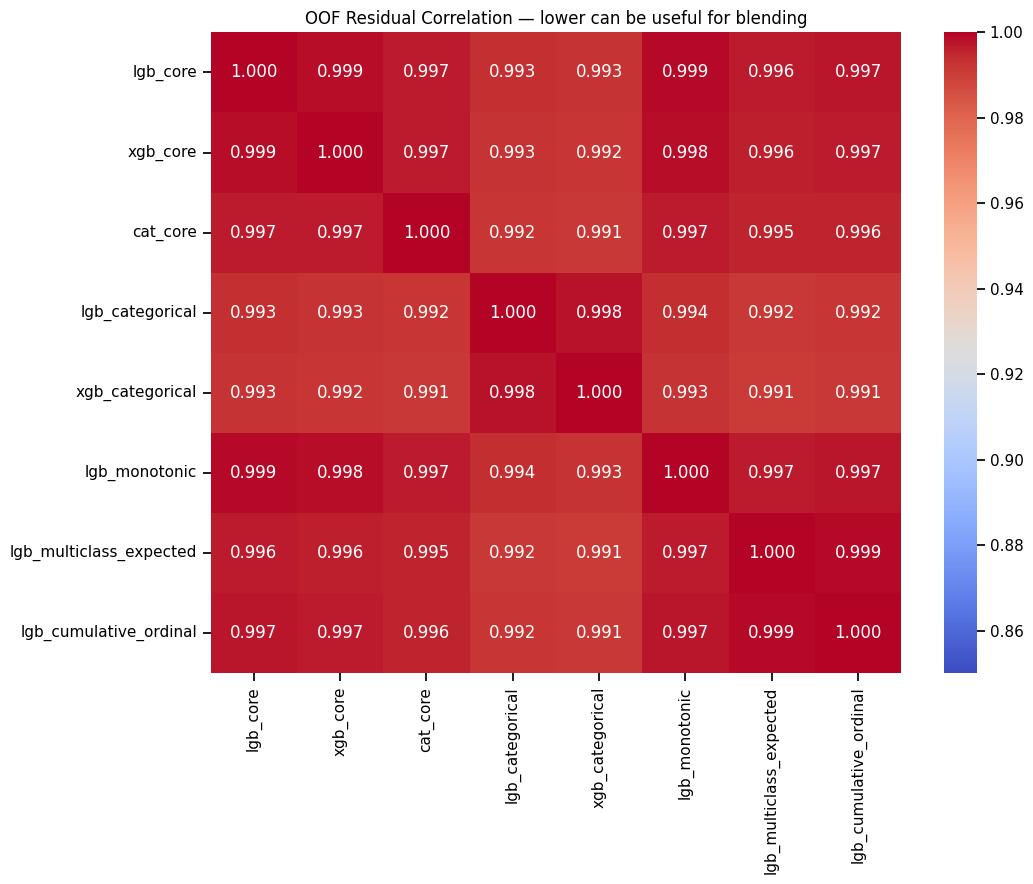

In [24]:
residuals={b:y-oof_cont[b] for b in valid_branches}
resid_corr=pd.DataFrame({b:residuals[b] for b in valid_branches}).corr()
display(resid_corr.style.background_gradient(cmap="coolwarm",vmin=0.85,vmax=1.0).format("{:.4f}"))

plt.figure(figsize=(11,9)); sns.heatmap(resid_corr,annot=True,fmt=".3f",cmap="coolwarm",vmin=0.85,vmax=1.0)
plt.title("OOF Residual Correlation — lower can be useful for blending"); plt.tight_layout(); plt.show()


### 7.3 Greedy OOF blend selection

Start from the proven three-model regression core. A sidecar is admitted only if a small non-negative blend improves **cross-fitted QWK** by at least `MIN_BRANCH_BLEND_GAIN`. This deliberately prevents a high-variance optimizer from inventing tiny gains.


In [25]:
current_oof=core_oof.copy(); current_test=core_test.copy()
current_score=core_cross
selected_steps=[]
remaining=[b for b in valid_branches if b not in core_names]

for step in range(CFG.MAX_SELECTED_SIDECARS):
    best=None
    for b in remaining:
        for alpha in CFG.GREEDY_ALPHA_GRID:
            cand=(1-alpha)*current_oof+alpha*oof_cont[b]
            score,_,_=crossfit_threshold_score(y,cand,primary_fold_id)
            rec={"branch":b,"alpha":float(alpha),"score":float(score),"gain":float(score-current_score),
                 "residual_corr_to_current":float(np.corrcoef(y-current_oof,y-oof_cont[b])[0,1])}
            if best is None or rec["score"]>best["score"]:
                best=rec
    if best is None or best["gain"]<CFG.MIN_BRANCH_BLEND_GAIN:
        print("Stop greedy selection. Best remaining gain:", None if best is None else best["gain"])
        break
    b=best["branch"]; a=best["alpha"]
    current_oof=(1-a)*current_oof+a*oof_cont[b]
    current_test=(1-a)*current_test+a*test_cont[b]
    current_score=best["score"]
    selected_steps.append(best)
    remaining.remove(b)
    print("Accepted:",best)

display(pd.DataFrame(selected_steps))

final_oof_cont=current_oof
final_test_cont_raw=current_test
final_thresholds,final_global_qwk=optimize_thresholds(y,final_oof_cont)
final_cross_qwk,final_cross_labels,final_cross_thresholds=crossfit_threshold_score(y,final_oof_cont,primary_fold_id)
print("Final global OOF QWK:",round(final_global_qwk,6))
print("Final cross-fitted OOF QWK:",round(final_cross_qwk,6))
print("Final thresholds:",np.round(final_thresholds,6))
print("Gain over repeated-CV core:",round(final_cross_qwk-core_cross,6))
print("Gain over historical V1 crossfit:",round(final_cross_qwk-CFG.V1_CROSSFIT_OOF,6))


Accepted: {'branch': 'lgb_multiclass_expected', 'alpha': 0.05, 'score': 0.4811099714315612, 'gain': 0.0011778936172991417, 'residual_corr_to_current': 0.9968571953993338}
Stop greedy selection. Best remaining gain: -9.735788969233994e-06


,branch,alpha,score,gain,residual_corr_to_current
0,lgb_multiclass_expected,0.05,0.48111,0.001178,0.996857


Final global OOF QWK: 0.481711
Final cross-fitted OOF QWK: 0.48111
Final thresholds: [1.563883 2.025374 2.591051]
Gain over repeated-CV core: 0.001178
Gain over historical V1 crossfit: 0.001448


### 7.4 Boundary / confusion analysis


In [26]:
final_oof_class=apply_thresholds(final_oof_cont,final_thresholds)
conf=pd.crosstab(pd.Series(y,name="actual"),pd.Series(final_cross_labels,name="crossfit_prediction"),normalize="index")
display(conf.style.format("{:.1%}"))

boundary_rows=[]
for k in [1,2,3]:
    boundary_rows.append({"boundary":f"y>{k}","auc":roc_auc_score((y>k).astype(int),final_oof_cont)})
display(pd.DataFrame(boundary_rows))

mean_by_class=pd.DataFrame({"y":y,"score":final_oof_cont}).groupby("y").score.agg(["mean","std","median"])
display(mean_by_class)


crossfit_prediction,1,2,3,4
actual,,,,
1,72.5%,25.7%,1.6%,0.1%
2,33.1%,54.8%,11.2%,0.9%
3,4.9%,35.1%,47.3%,12.7%
4,16.0%,21.5%,36.2%,26.3%


,boundary,auc
0,y>1,0.779768
1,y>2,0.872330
2,y>3,0.808832


,mean,std,median
y,,,
1,1.445045,0.232752,1.415095
2,1.701268,0.282523,1.679838
3,2.121934,0.349537,2.097904
4,2.165352,0.522544,2.202163


### 7.5 OOF vs test distribution sanity check


In [27]:
# Test still contains duplicate raw rows here; distribution sanity is row-level.
print("Continuous KS OOF vs raw test:",ks_2samp(final_oof_cont,final_test_cont_raw).statistic)
qs=[0.01,0.1,0.25,0.5,0.75,0.9,0.99]
display(pd.DataFrame({"q":qs,"oof":np.quantile(final_oof_cont,qs),"test":np.quantile(final_test_cont_raw,qs)}))


Continuous KS OOF vs raw test: 0.009942248597466063


,q,oof,test
0,0.01,1.083903,1.080458
1,0.10,1.234296,1.236699
2,0.25,1.372524,1.378388
3,0.50,1.568128,1.574009
4,0.75,1.784170,1.787346
5,0.90,2.014675,2.017490
6,0.99,2.586164,2.600031


## 8. Final Submission — FIXED Unique-ID Contract


In [28]:
# IMPORTANT: Kaggle evaluator expects one row per UNIQUE test_final.id (23,666),
# not 23,902 raw test rows and not the misleading sample_submission row IDs.
row_level_pred=pd.DataFrame({
    CFG.ID_COL:test[CFG.ID_COL].values,
    "continuous_prediction":final_test_cont_raw,
})

# Exact duplicate raw rows should produce the same prediction. Mean is a safe deterministic aggregation.
dup_spread=row_level_pred.groupby(CFG.ID_COL)["continuous_prediction"].agg(lambda s: float(s.max()-s.min()))
print("Max prediction spread within duplicate test id:",dup_spread.max())

submission_cont=(
    row_level_pred.groupby(CFG.ID_COL,sort=False,as_index=False)["continuous_prediction"].mean()
)
submission_cont[CFG.TARGET]=apply_thresholds(submission_cont["continuous_prediction"].values,final_thresholds).astype(int)
submission=submission_cont[[CFG.ID_COL,CFG.TARGET]].copy()

assert len(submission)==CFG.EXPECTED_UNIQUE_TEST_IDS, len(submission)
assert submission[CFG.ID_COL].is_unique
assert submission[CFG.TARGET].isin([1,2,3,4]).all()
assert submission.isna().sum().sum()==0
# Preserve first-appearance order of unique test ids, exactly like the V1 fixed submission that scored 0.48003.
assert submission[CFG.ID_COL].tolist()==test[CFG.ID_COL].drop_duplicates().tolist()

display(submission.head(10))
print("Submission rows:",len(submission))
print(submission[CFG.TARGET].value_counts(normalize=True).sort_index())

submission_path=CFG.OUTPUT_DIR/"submission_v2.csv"
submission.to_csv(submission_path,index=False)
print("Saved:",submission_path)


Max prediction spread within duplicate test id: 0.0


,id,life_satisfaction
0,10373,1
1,27800,2
2,115533,1
3,112254,1
4,10379,1
5,37613,2
6,82491,1
7,78738,1
8,53512,1
9,72128,2


Submission rows: 23666
life_satisfaction
1    0.486690
2    0.415871
3    0.087002
4    0.010437
Name: proportion, dtype: float64
Saved: /kaggle/working/oqdq5_v2/submission_v2.csv


## 9. Save Reproducibility Artifacts


In [29]:

# V8.1: raw cumulative probabilities from the exact V2 ordinal branch.
assert "lgb_cumulative_ordinal" in valid_branches
assert np.all(ORDINAL_OOF_COUNT==CFG.N_REPEATS)
assert np.all(ORDINAL_OOF_REPEAT_COUNT==1)
ordinal_oof_probs_by_repeat=ORDINAL_OOF_BY_REPEAT.copy()
ordinal_oof_probs=ORDINAL_OOF_SUM/CFG.N_REPEATS
ordinal_test_probs=ORDINAL_TEST_SUM/(CFG.N_REPEATS*CFG.N_FOLDS)
assert np.isfinite(ordinal_oof_probs).all() and np.isfinite(ordinal_test_probs).all()
assert np.all(ordinal_oof_probs[:,0]>=ordinal_oof_probs[:,1]) and np.all(ordinal_oof_probs[:,1]>=ordinal_oof_probs[:,2])
assert np.all(ordinal_test_probs[:,0]>=ordinal_test_probs[:,1]) and np.all(ordinal_test_probs[:,1]>=ordinal_test_probs[:,2])
assert np.allclose(1.0+ordinal_oof_probs.sum(1),oof_cont["lgb_cumulative_ordinal"],rtol=0,atol=1e-12)
assert np.allclose(1.0+ordinal_test_probs.sum(1),test_cont["lgb_cumulative_ordinal"],rtol=0,atol=1e-12)

oof_df=pd.DataFrame({CFG.ID_COL:train[CFG.ID_COL].values,CFG.TARGET:y,"primary_fold":primary_fold_id})
for b in valid_branches:
    oof_df[f"oof_{b}_continuous"]=oof_cont[b]
oof_df["oof_core_continuous"]=core_oof
oof_df["oof_final_continuous"]=final_oof_cont
oof_df["oof_final_crossfit_class"]=final_cross_labels

for j,boundary in enumerate([1,2,3]):
    oof_df[f"oof_lgb_cumulative_p_y_gt_{boundary}"]=ordinal_oof_probs[:,j]

# Row-level test artifacts retain duplicates for reproducibility; submission separately aggregates by id.
test_pred_df=pd.DataFrame({"row_index":np.arange(len(test)),CFG.ID_COL:test[CFG.ID_COL].values})
for b in valid_branches:
    test_pred_df[f"test_{b}_continuous"]=test_cont[b]
test_pred_df["test_core_continuous"]=core_test
test_pred_df["test_final_continuous"]=final_test_cont_raw

for j,boundary in enumerate([1,2,3]):
    test_pred_df[f"test_lgb_cumulative_p_y_gt_{boundary}"]=ordinal_test_probs[:,j]

feature_selection_df=pd.DataFrame(feature_selection_rows)
feature_importance_df=pd.DataFrame(feature_importance_rows)
fold_audit_df=pd.DataFrame(fold_audit_rows)

summary={
    "version":CFG.VERSION,
    "competition":CFG.COMPETITION_NAME,
    "v1_public_lb_reference":CFG.V1_PUBLIC_LB,
    "v1_crossfit_oof_reference":CFG.V1_CROSSFIT_OOF,
    "current_top1_public_reference":CFG.CURRENT_TOP1_PUBLIC,
    "n_train":len(train),"n_test_raw":len(test),"n_test_unique_id":int(test[CFG.ID_COL].nunique()),
    "n_repeats":CFG.N_REPEATS,"n_folds":CFG.N_FOLDS,
    "valid_branches":valid_branches,
    "core_global_qwk":float(core_global),"core_crossfit_qwk":float(core_cross),
    "final_global_qwk":float(final_global_qwk),"final_crossfit_qwk":float(final_cross_qwk),
    "final_thresholds":[float(x) for x in final_thresholds],
    "selected_sidecars":selected_steps,
    "submission_rows":len(submission),
    "notes":[
        "2x5 repeated StratifiedGroupKFold groups=id",
        "Nested fold-safe feature selection; explainability probe does not control final outer folds",
        "Raw + dictionary-valid semantic + nonstandard survey-code representation",
        "Native categorical LightGBM/XGBoost candidate branches",
        "Monotonic semantic LightGBM diversity branch",
        "Multiclass expected-value and cumulative ordinal sidecars",
        "No scaling, SMOTE, generic imputation, or survey_weight sample weighting",
        "Submission aggregated to one row per unique test_final.id (23,666) before thresholding",
    ],
}

paths={
    "oof":CFG.OUTPUT_DIR/"oof_v2.csv",
    "test_predictions":CFG.OUTPUT_DIR/"test_predictions_v2.csv",
    "branch_evaluation":CFG.OUTPUT_DIR/"branch_evaluation_v2.csv",
    "feature_selection":CFG.OUTPUT_DIR/"feature_selection_v2.csv",
    "feature_importance":CFG.OUTPUT_DIR/"feature_importance_v2.csv",
    "fold_audit":CFG.OUTPUT_DIR/"fold_audit_v2.csv",
    "semantic_audit":CFG.OUTPUT_DIR/"semantic_code_audit_v2.csv",
    "summary":CFG.OUTPUT_DIR/"v2_summary.json",
}

oof_df.to_csv(paths["oof"],index=False)
test_pred_df.to_csv(paths["test_predictions"],index=False)
branch_eval_df.to_csv(paths["branch_evaluation"],index=False)
feature_selection_df.to_csv(paths["feature_selection"],index=False)
feature_importance_df.to_csv(paths["feature_importance"],index=False)
fold_audit_df.to_csv(paths["fold_audit"],index=False)
semantic_audit_df.to_csv(paths["semantic_audit"],index=False)
with open(paths["summary"],"w") as f: json.dump(summary,f,indent=2)

print("Artifacts:")
print(" -",submission_path)
for p in paths.values(): print(" -",p)
display(pd.Series(summary).to_frame("value"))


Artifacts:
 - /kaggle/working/oqdq5_v2/submission_v2.csv
 - /kaggle/working/oqdq5_v2/oof_v2.csv
 - /kaggle/working/oqdq5_v2/test_predictions_v2.csv
 - /kaggle/working/oqdq5_v2/branch_evaluation_v2.csv
 - /kaggle/working/oqdq5_v2/feature_selection_v2.csv
 - /kaggle/working/oqdq5_v2/feature_importance_v2.csv
 - /kaggle/working/oqdq5_v2/fold_audit_v2.csv
 - /kaggle/working/oqdq5_v2/semantic_code_audit_v2.csv
 - /kaggle/working/oqdq5_v2/v2_summary.json


,value
version,v2
competition,Objective Quest DATAQUEST 5.0
v1_public_lb_reference,0.48003
v1_crossfit_oof_reference,0.479662
current_top1_public_reference,0.48853
n_train,95609
n_test_raw,23902
n_test_unique_id,23666
n_repeats,2
n_folds,5


## V2 Decision Rules

Interpret V2 using the **cross-fitted OOF**, not the global threshold score alone:

- `< 0.482`: reject V2 architecture / investigate failed branches.
- `0.482–0.484`: real improvement, but likely not enough to attack #1.
- `0.484–0.486`: worth a leaderboard submission.
- `0.486–0.488`: strong candidate.
- `≥ 0.488`: serious Top-1 attack.

Also inspect:

1. whether gain appears across both repeats, not one lucky fold;
2. whether sidecars lower residual correlation and actually improve the core blend;
3. boundary `y>1` AUC, because class 1↔2 dominated V1's weighted disagreement;
4. OOF/test distribution alignment;
5. final submission **must be exactly 23,666 unique IDs**.


---

# Objective Quest DATAQUEST 5.0 — V8.1 EXAONE Conditional Repair

The cells above are the original executed V2 notebook. Only the cumulative
LightGBM return values and artifact columns were extended so its already-computed
`P(y>1)`, `P(y>2)`, and `P(y>3)` heads survive. The anchor score, branch selection,
thresholds, and submission recipe are unchanged.

Run on Kaggle with **T4 x2** and **Internet ON**. V2 must reproduce at
`honest crossfit >= 0.4810`; otherwise execution stops before EXAONE.


In [30]:
V81_VERSION = "v8_1_exaone_conditional"
V81_PROBE_FOLDS = [0, 2, 3]
V81_ANCHOR_CF_MIN = 0.4810
V81_FOLD0_CATASTROPHIC_DELTA = -0.003
V81_PROMOTE_MIN_WINS = 2
V81_PROMOTE_MEAN_DELTA = 0.002
V81_MIN_SAFE_GAIN = 0.0005
V81_MIN_STABLE_FOLDS = 3
V81_WORTH_CF = 0.485
V81_WORTH_GAIN = 0.003
V81_WORTH_POSITIVE_FOLDS = 4
V81_SERIOUS_CF = 0.489
V81_SERIOUS_B1 = 0.786
V81_PROBE_ENSEMBLE = 4
V81_FULL_ENSEMBLE = 8
V81_MISSING_FLAG_TOPK = 16
V81_EXAONE_VRAM_BYTES = 13 << 30

RUN_EXAONE = True
EXAONE_RUNTIME_REPO = "https://github.com/LGAI-Research/EXAONE-Tabular.git"
EXAONE_RUNTIME_REVISION = "8638e07d09fad154249bd75ba4786181491f7025"
EXAONE_HF_REPO = "LG-AI-Research/EXAONE-Tabular"
EXAONE_HF_REVISION = "093ad1c2613e1e95d26df8610451d2e02ed53cbe"
EXAONE_CHECKPOINT = "exaone-tabular-classifier-v1_default.safetensors"
EXAONE_CHECKPOINT_SHA256 = "2aa723e024e5c56c778d6c79cc3cee7675d1b6a03c06fa08c80e620e228b224d"


In [31]:
import numpy as np
import pandas as pd
from sklearn.model_selection import StratifiedGroupKFold


def anchor_gate(anchor_cf, minimum=0.4810):
    assert float(anchor_cf) >= minimum, f"V2 anchor gate failed: {anchor_cf:.9f} < {minimum:.4f}; EXAONE must not run"


def validate_cumulative_heads(heads):
    p=np.asarray(heads,dtype=float)
    assert p.ndim==2 and p.shape[1]==3 and np.isfinite(p).all()
    assert np.all((0<=p)&(p<=1))
    assert np.all(p[:,0]>=p[:,1]) and np.all(p[:,1]>=p[:,2])
    return p


def p12_from_cumulative(pgt1,pgt2,eps=1e-6):
    a=np.asarray(pgt1,dtype=float);b=np.asarray(pgt2,dtype=float)
    assert a.shape==b.shape and np.all(a+1e-12>=b)
    return np.clip((a-b)/np.maximum(1.0-b,eps),eps,1.0-eps)


def conditional_score(p12,pgt2,pgt3):
    p12=np.clip(np.asarray(p12,dtype=float),1e-6,1-1e-6)
    pgt2=np.clip(np.asarray(pgt2,dtype=float),0,1)
    pgt3=np.minimum(np.clip(np.asarray(pgt3,dtype=float),0,1),pgt2)
    pgt1=pgt2+(1.0-pgt2)*p12
    return 1.0+pgt1+pgt2+pgt3


def fold0_catastrophic(delta_auc_1v2,delta_b1,cut=-0.003):
    return float(delta_auc_1v2)<cut and float(delta_b1)<cut


def probe_promoted(rows,min_wins=2,min_mean_delta=0.002):
    if len(rows)!=3 or any(r.get("error") for r in rows):
        return False,{"wins":0,"mean_delta_auc_1v2":float("nan"),"mean_delta_b1":float("nan")}
    wins=sum(float(r["delta_auc_1v2"])>0 or float(r["delta_b1"])>0 for r in rows)
    mean_auc=float(np.mean([r["delta_auc_1v2"] for r in rows]))
    mean_b1=float(np.mean([r["delta_b1"] for r in rows]))
    summary={"wins":int(wins),"mean_delta_auc_1v2":mean_auc,"mean_delta_b1":mean_b1}
    return bool(wins>=min_wins and (mean_auc>=min_mean_delta or mean_b1>=min_mean_delta)),summary


def full_fold_batches(promoted,gpu_count):
    if not promoted:return []
    if gpu_count>=2:return [[(0,0),(1,1)],[(2,0),(3,1)],[(4,0)]]
    return [[(f,0)] for f in range(5)]



def meta_crossfit_splits(outer_fold_ids,labels,group_ids):
    outer_fold_ids=np.asarray(outer_fold_ids);labels=np.asarray(labels);group_ids=np.asarray(group_ids)
    for outer_fold in sorted(np.unique(outer_fold_ids)):
        outer_idx=np.flatnonzero(outer_fold_ids==outer_fold)
        splitter=StratifiedGroupKFold(n_splits=2,shuffle=True,random_state=7300+int(outer_fold))
        for train_local,valid_local in splitter.split(outer_idx,labels[outer_idx],groups=group_ids[outer_idx]):
            train_idx=outer_idx[train_local];valid_idx=outer_idx[valid_local]
            assert not set(group_ids[train_idx]).intersection(group_ids[valid_idx])
            yield int(outer_fold),train_idx,valid_idx


def candidate_accepted(anchor_cf,candidate_cf,positive_folds,min_gain=0.0005,min_positive_folds=3):
    return bool(float(candidate_cf)>float(anchor_cf)+float(min_gain) and int(positive_folds)>=min_positive_folds)



def submission_decision_flags(anchor_cf,candidate_cf,positive_folds,b1):
    gain=float(candidate_cf)-float(anchor_cf)
    return {
        "worth_submission":bool(float(candidate_cf)>=0.485 and gain>=0.003 and int(positive_folds)>=4),
        "serious_top3_candidate":bool(float(candidate_cf)>=0.489 and float(b1)>=0.786),
    }


def submission_from_scores(ids,row_scores,thresholds,target_name):
    frame=pd.DataFrame({"id":np.asarray(ids),"score":np.asarray(row_scores,dtype=float)})
    grouped=frame.groupby("id",sort=False,as_index=False).score.mean()
    means=grouped.score.to_numpy()
    grouped[target_name]=(np.digitize(means,np.sort(np.asarray(thresholds,dtype=float)))+1).astype(int)
    return grouped[["id",target_name]].copy(),means


def safe_select(use_candidate,anchor_oof,anchor_test,anchor_thresholds,anchor_submission,
                candidate_oof,candidate_test,candidate_thresholds,candidate_submission):
    if use_candidate:
        return (np.asarray(candidate_oof).copy(),np.asarray(candidate_test).copy(),
                np.asarray(candidate_thresholds).copy(),candidate_submission.copy(deep=True))
    selected=(np.asarray(anchor_oof).copy(),np.asarray(anchor_test).copy(),
              np.asarray(anchor_thresholds).copy(),anchor_submission.copy(deep=True))
    assert np.array_equal(selected[0],np.asarray(anchor_oof))
    assert np.array_equal(selected[1],np.asarray(anchor_test))
    assert np.array_equal(selected[2],np.asarray(anchor_thresholds))
    pd.testing.assert_frame_equal(selected[3],anchor_submission,check_exact=True)
    return selected


## 10. Freeze and gate the exact V2 anchor

This cell runs before any EXAONE environment mutation. A failed reproduction
assertion stops the notebook immediately.


In [32]:
import hashlib, importlib, platform, shutil, subprocess, sys, time
from pathlib import Path

V81_OUT=Path("/kaggle/working/oqdq5_v8_1") if Path("/kaggle/working").exists() else Path("./oqdq5_v8_1")
V81_OUT.mkdir(parents=True,exist_ok=True)

ANCHOR_CF=float(final_cross_qwk)
anchor_gate(ANCHOR_CF,V81_ANCHOR_CF_MIN)
ANCHOR_OOF=np.asarray(final_oof_cont,dtype=np.float64).copy()
ANCHOR_TEST=np.asarray(final_test_cont_raw,dtype=np.float64).copy()
ANCHOR_THRESHOLDS=np.asarray(final_thresholds,dtype=np.float64).copy()
ANCHOR_SUBMISSION=submission.copy(deep=True)
ANCHOR_HEADS_OOF=validate_cumulative_heads(ordinal_oof_probs).copy()
ANCHOR_HEADS_TEST=validate_cumulative_heads(ordinal_test_probs).copy()
ANCHOR_P12_OOF=p12_from_cumulative(ANCHOR_HEADS_OOF[:,0],ANCHOR_HEADS_OOF[:,1])
ANCHOR_HEADS_OOF_META=validate_cumulative_heads(ordinal_oof_probs_by_repeat[0]).copy()
ANCHOR_P12_META_OOF=p12_from_cumulative(ANCHOR_HEADS_OOF_META[:,0],ANCHOR_HEADS_OOF_META[:,1])
ANCHOR_P12_TEST=p12_from_cumulative(ANCHOR_HEADS_TEST[:,0],ANCHOR_HEADS_TEST[:,1])

assert np.array_equal(ANCHOR_OOF,final_oof_cont)
assert np.array_equal(ANCHOR_TEST,final_test_cont_raw)
assert np.array_equal(ANCHOR_THRESHOLDS,final_thresholds)
pd.testing.assert_frame_equal(ANCHOR_SUBMISSION,submission,check_exact=True)

ANCHOR_SUBMISSION_PATH=V81_OUT/"submission_exact_v2.csv"
ANCHOR_SUBMISSION.to_csv(ANCHOR_SUBMISSION_PATH,index=False)
np.savez_compressed(V81_OUT/"exact_v2_anchor.npz",oof=ANCHOR_OOF,test=ANCHOR_TEST,
                    thresholds=ANCHOR_THRESHOLDS,heads_oof=ANCHOR_HEADS_OOF,heads_oof_repeat0=ANCHOR_HEADS_OOF_META,heads_test=ANCHOR_HEADS_TEST)
print(f"Exact V2 anchor passed: CF={ANCHOR_CF:.9f}")


Exact V2 anchor passed: CF=0.481109971


## 11. Isolated official EXAONE runtime

EXAONE is installed into a dedicated venv after V2 is frozen. Workers are
short-lived subprocesses, so upgraded NumPy/scikit-learn cannot alter V2.


In [33]:
EXAONE_WORKER_SOURCE = r"""
import argparse
import hashlib
import importlib.metadata as metadata
import json
import os
import time
from pathlib import Path

import numpy as np


def sha256_file(path,chunk=2**20):
    digest=hashlib.sha256()
    with open(path,"rb") as handle:
        while block:=handle.read(chunk):digest.update(block)
    return digest.hexdigest()


def positive_probability(model,X):
    probabilities=np.asarray(model.predict_proba(X),dtype=np.float64)
    classes=np.asarray(model.classes_)
    match=np.flatnonzero(classes==1)
    assert len(match)==1,classes
    result=probabilities[:,int(match[0])]
    assert np.isfinite(result).all() and np.all((0<=result)&(result<=1))
    return result


parser=argparse.ArgumentParser()
parser.add_argument("--mode",choices=["preflight","run"],required=True)
parser.add_argument("--repo",required=True)
parser.add_argument("--revision",required=True)
parser.add_argument("--checkpoint",required=True)
parser.add_argument("--checkpoint-sha256",required=True)
parser.add_argument("--runtime-revision",required=True)
parser.add_argument("--cache",required=True)
parser.add_argument("--output",required=True)
parser.add_argument("--input")
parser.add_argument("--ensemble",type=int,default=1)
parser.add_argument("--seed",type=int,default=0)
parser.add_argument("--max-vram-bytes",type=int,required=True)
args=parser.parse_args()

os.environ["HF_HOME"]=args.cache
os.environ.pop("EXAONETABULAR_CLASSIFIER_WEIGHTS",None)
import torch
from huggingface_hub import hf_hub_download
from exaonetabular import EXAONETabularClassifier

assert torch.cuda.is_available(),"EXAONE requires a Kaggle GPU"
torch.cuda.set_device(0)
checkpoint=hf_hub_download(repo_id=args.repo,filename=args.checkpoint,revision=args.revision)
checkpoint_sha=sha256_file(checkpoint)
assert checkpoint_sha==args.checkpoint_sha256,(checkpoint_sha,args.checkpoint_sha256)

distribution=metadata.distribution("exaonetabular")
direct=json.loads(distribution.read_text("direct_url.json") or "{}")
installed_commit=direct.get("vcs_info",{}).get("commit_id")
assert installed_commit==args.runtime_revision,(installed_commit,args.runtime_revision)

started=time.time()
model=EXAONETabularClassifier.from_pretrained(
    weights=checkpoint,device="cuda:0",ensemble_count=args.ensemble,seed=args.seed,
    revision=args.revision,max_vram_bytes=args.max_vram_bytes,
)
common={
    "package_version":distribution.version,
    "runtime_commit":installed_commit,
    "hf_revision":args.revision,
    "checkpoint":args.checkpoint,
    "checkpoint_path":str(checkpoint),
    "checkpoint_sha256":checkpoint_sha,
    "torch":torch.__version__,
    "gpu":torch.cuda.get_device_name(0),
}
if args.mode=="preflight":
    common["runtime_sec"]=time.time()-started
    Path(args.output).write_text(json.dumps(common,indent=2))
else:
    data=np.load(args.input,allow_pickle=False)
    X_train=np.asarray(data["X_train"],dtype=np.float32)
    y_train=np.asarray(data["y_train"],dtype=np.int64)
    X_valid=np.asarray(data["X_valid"],dtype=np.float32)
    X_test=np.asarray(data["X_test"],dtype=np.float32)
    assert X_train.ndim==X_valid.ndim==X_test.ndim==2
    assert X_train.shape[1]==X_valid.shape[1]==X_test.shape[1]
    assert set(np.unique(y_train).tolist())=={0,1}
    assert np.all(np.isfinite(X_train)|np.isnan(X_train))
    model.fit(X_train,y_train)
    p_valid=positive_probability(model,X_valid)
    p_test=positive_probability(model,X_test) if len(X_test) else np.empty(0,dtype=np.float64)
    selected=np.asarray(getattr(model,"selected_feature_indices_",[]),dtype=np.int64)
    np.savez(args.output,p_valid=p_valid,p_test=p_test,selected_feature_indices=selected,
             runtime_sec=np.array([time.time()-started],dtype=np.float64))
"""


In [34]:
EXAONE_VENV=V81_OUT/"exaone_venv"
EXAONE_PYTHON=EXAONE_VENV/"bin"/"python"
EXAONE_CACHE=V81_OUT/"exaone_hf_cache"
EXAONE_CACHE.mkdir(parents=True,exist_ok=True)
EXAONE_WORKER=V81_OUT/"exaone_worker.py"
EXAONE_WORKER.write_text(EXAONE_WORKER_SOURCE)
EXAONE_RUNTIME_READY=False
EXAONE_RUNTIME_ERROR=None
EXAONE_RUNTIME_MANIFEST={}

def exaone_worker_command(mode,output,input_path=None,ensemble=1,seed=0):
    command=[str(EXAONE_PYTHON),str(EXAONE_WORKER),"--mode",mode,
        "--repo",EXAONE_HF_REPO,"--revision",EXAONE_HF_REVISION,
        "--checkpoint",EXAONE_CHECKPOINT,"--checkpoint-sha256",EXAONE_CHECKPOINT_SHA256,
        "--runtime-revision",EXAONE_RUNTIME_REVISION,"--cache",str(EXAONE_CACHE),
        "--output",str(output),"--ensemble",str(ensemble),"--seed",str(seed),
        "--max-vram-bytes",str(V81_EXAONE_VRAM_BYTES)]
    if input_path is not None:command.extend(["--input",str(input_path)])
    return command

if RUN_EXAONE:
    try:
        if not EXAONE_PYTHON.exists():
            subprocess.check_call([sys.executable,"-m","venv","--system-site-packages",str(EXAONE_VENV)])
        package=f"exaonetabular @ git+{EXAONE_RUNTIME_REPO}@{EXAONE_RUNTIME_REVISION}"
        subprocess.check_call([str(EXAONE_PYTHON),"-m","pip","install","-q","--disable-pip-version-check",package])
        worker_freeze=subprocess.check_output([str(EXAONE_PYTHON),"-m","pip","freeze"],text=True)
        (V81_OUT/"exaone_worker_freeze.txt").write_text(worker_freeze)
        preflight_path=V81_OUT/"exaone_runtime_manifest.json"
        env=os.environ.copy();env["CUDA_VISIBLE_DEVICES"]="0";env["HF_HOME"]=str(EXAONE_CACHE)
        env["PYTORCH_CUDA_ALLOC_CONF"]="expandable_segments:True"
        subprocess.check_call(exaone_worker_command("preflight",preflight_path,ensemble=1,seed=8100),env=env)
        EXAONE_RUNTIME_MANIFEST=json.loads(preflight_path.read_text())
        EXAONE_RUNTIME_READY=True
    except Exception as error:
        EXAONE_RUNTIME_ERROR=repr(error)
        EXAONE_RUNTIME_MANIFEST={"error":EXAONE_RUNTIME_ERROR}
        (V81_OUT/"exaone_runtime_manifest.json").write_text(json.dumps(EXAONE_RUNTIME_MANIFEST,indent=2))
        print("EXAONE runtime unavailable; exact V2 fallback remains armed:",EXAONE_RUNTIME_ERROR)

print("EXAONE runtime ready:",EXAONE_RUNTIME_READY)
print(json.dumps(EXAONE_RUNTIME_MANIFEST,indent=2))


EXAONE runtime unavailable; exact V2 fallback remains armed: CalledProcessError(1, ['/usr/bin/python3', '-m', 'venv', '--system-site-packages', '/kaggle/working/oqdq5_v8_1/exaone_venv'])
EXAONE runtime ready: False
{
  "error": "CalledProcessError(1, ['/usr/bin/python3', '-m', 'venv', '--system-site-packages', '/kaggle/working/oqdq5_v8_1/exaone_venv'])"
}


Error: Command '['/kaggle/working/oqdq5_v8_1/exaone_venv/bin/python3', '-m', 'ensurepip', '--upgrade', '--default-pip']' returned non-zero exit status 1.


## 12. Numeric competition-only EXAONE view and worker orchestration

Only raw competition predictors are used. IDs and target are excluded; known
continuous sentinel responses become NaN plus flags. No TE, one-hot encoding,
scaling, codebook augmentation, or external data is used.


In [35]:
EXAONE_EXCLUDE={CFG.TARGET,CFG.ID_COL,CFG.HOUSEHOLD_COL}
EXAONE_BASE_FEATURES=[c for c in test.columns if c not in EXAONE_EXCLUDE]
EXAONE_CONTINUOUS_SPECIAL={c:set(v) for c,v in SPECIAL_CODES.items() if c in EXAONE_BASE_FEATURES}

def make_exaone_numeric(df):
    frame=df[EXAONE_BASE_FEATURES].copy()
    for column in EXAONE_BASE_FEATURES:frame[column]=pd.to_numeric(frame[column],errors="coerce")
    frame=frame.replace([np.inf,-np.inf],np.nan)
    for column,codes in EXAONE_CONTINUOUS_SPECIAL.items():
        special=frame[column].isin(codes)
        frame[f"{column}__special_response"]=special.astype(np.float32)
        frame.loc[special,column]=np.nan
    return frame.astype(np.float32)

EXAONE_NUM_TRAIN=make_exaone_numeric(train)
EXAONE_NUM_TEST=make_exaone_numeric(test)
assert EXAONE_NUM_TRAIN.columns.tolist()==EXAONE_NUM_TEST.columns.tolist()

def select_boundary_missing_flags(frame,labels,topk=16):
    rows=[];labels=np.asarray(labels,dtype=float)
    for column in frame.columns:
        missing=frame[column].isna().to_numpy();rate=float(missing.mean())
        if rate<0.02 or rate>0.98 or missing.sum()<100 or (~missing).sum()<100:continue
        delta=abs(float(labels[missing].mean())-float(labels[~missing].mean()))
        rows.append((delta,column,rate))
    return [column for _,column,_ in sorted(rows,reverse=True)[:topk]]


def visible_gpu_count():
    if not shutil.which("nvidia-smi"):return 0
    try:
        output=subprocess.check_output(["nvidia-smi","--query-gpu=index","--format=csv,noheader"],text=True)
        return len([line for line in output.splitlines() if line.strip()])
    except Exception:
        return 0


def prepare_exaone_fold(fold,stage,predict_test):
    validation=np.flatnonzero(primary_fold_id==fold)
    outer_train=np.flatnonzero(primary_fold_id!=fold)
    boundary_train=outer_train[np.isin(y[outer_train],[1,2])]
    labels=(y[boundary_train]==2).astype(np.int64)
    A=EXAONE_NUM_TRAIN.iloc[boundary_train].copy()
    B=EXAONE_NUM_TRAIN.iloc[validation].copy()
    C=EXAONE_NUM_TEST.copy() if predict_test else EXAONE_NUM_TEST.iloc[:0].copy()
    flags=select_boundary_missing_flags(A,labels,V81_MISSING_FLAG_TOPK)
    for column in flags:
        for frame in (A,B,C):frame[f"{column}__missing_flag"]=frame[column].isna().astype(np.float32)
    input_path=V81_OUT/f"{stage}_fold{fold}_input.npz"
    output_path=V81_OUT/f"{stage}_fold{fold}_output.npz"
    np.savez(input_path,X_train=np.ascontiguousarray(A.to_numpy(np.float32)),y_train=labels,
             X_valid=np.ascontiguousarray(B.to_numpy(np.float32)),X_test=np.ascontiguousarray(C.to_numpy(np.float32)))
    return {"fold":fold,"validation":validation,"input":input_path,"output":output_path,
            "features":A.columns.tolist(),"missing_flags":flags}

def launch_and_wait_workers(specs,popen_factory=subprocess.Popen,open_file=open):
    jobs=[];complete=False
    try:
        for prepared,command,env,log_path in specs:
            handle=open_file(log_path,"w")
            try:process=popen_factory(command,stdout=handle,stderr=subprocess.STDOUT,env=env)
            except BaseException:
                handle.close()
                raise
            jobs.append((prepared,process,handle,log_path))
        statuses=[(prepared,process.wait(),log_path) for prepared,process,_,log_path in jobs]
        complete=True
        return statuses
    finally:
        if not complete:
            for _,process,_,_ in jobs:
                try:
                    if process.poll() is None:process.terminate()
                except Exception:pass
            for _,process,_,_ in jobs:
                try:
                    if process.poll() is None:
                        try:process.wait(timeout=30)
                        except subprocess.TimeoutExpired:
                            process.kill();process.wait()
                except Exception:pass
        for _,_,handle,_ in jobs:handle.close()


def run_exaone_batch(assignments,ensemble,stage,predict_test):
    prepared_jobs=[]
    try:
        for fold,_ in assignments:prepared_jobs.append(prepare_exaone_fold(fold,stage,predict_test))
        specs=[]
        for (_,gpu),prepared in zip(assignments,prepared_jobs):
            log_path=V81_OUT/f"{stage}_fold{prepared['fold']}.log"
            env=os.environ.copy();env["CUDA_VISIBLE_DEVICES"]=str(gpu);env["HF_HOME"]=str(EXAONE_CACHE)
            env["PYTORCH_CUDA_ALLOC_CONF"]="expandable_segments:True"
            command=exaone_worker_command("run",prepared["output"],prepared["input"],ensemble,
                                          seed=9100+prepared["fold"]*41+ensemble)
            specs.append((prepared,command,env,log_path))
        statuses=launch_and_wait_workers(specs)
        failures=[]
        for prepared,returncode,log_path in statuses:
            if returncode:
                tail=log_path.read_text(errors="replace")[-5000:]
                failures.append(f"EXAONE fold {prepared['fold']} failed ({returncode}):\n{tail}")
        if failures:raise RuntimeError("\n\n".join(failures))
        results={}
        for prepared,_,_ in statuses:
            with np.load(prepared["output"],allow_pickle=False) as payload:
                selected=payload["selected_feature_indices"].astype(int).tolist()
                result={"validation":prepared["validation"],"p_valid":payload["p_valid"].astype(float),
                        "p_test":payload["p_test"].astype(float),"runtime_sec":float(payload["runtime_sec"][0]),
                        "missing_flags":prepared["missing_flags"],
                        "selected_features":[prepared["features"][i] for i in selected]}
            assert len(result["p_valid"])==len(prepared["validation"])
            results[prepared["fold"]]=result
        return results
    finally:
        for prepared in prepared_jobs:prepared["input"].unlink(missing_ok=True)


print("EXAONE numeric width:",EXAONE_NUM_TRAIN.shape[1])


EXAONE numeric width: 182


## 13. Multi-fold EXAONE probe: folds 0, 2, 3

Fold 0 only rejects a catastrophic candidate when both requested deltas are
strictly below -0.003. A neutral fold always proceeds to folds 2 and 3.


In [36]:
from sklearn.metrics import roc_auc_score

def evaluate_specialist_fold(fold,p12):
    validation=np.flatnonzero(primary_fold_id==fold);yv=y[validation]
    mask12=np.isin(yv,[1,2]);target12=(yv[mask12]==2).astype(int)
    baseline12=ANCHOR_P12_OOF[validation][mask12]
    candidate12=np.asarray(p12)[mask12]
    conditional=conditional_score(p12,ANCHOR_HEADS_OOF[validation,1],ANCHOR_HEADS_OOF[validation,2])
    auc12=float(roc_auc_score(target12,candidate12));base_auc12=float(roc_auc_score(target12,baseline12))
    b1=float(roc_auc_score((yv>1).astype(int),conditional));base_b1=float(roc_auc_score((yv>1).astype(int),ANCHOR_OOF[validation]))
    return {"fold":int(fold),"auc_1v2":auc12,"v2_auc_1v2":base_auc12,"delta_auc_1v2":auc12-base_auc12,
            "b1":b1,"v2_b1":base_b1,"delta_b1":b1-base_b1,"error":None}

PROBE_ROWS=[];PROBE_P12={};PROBE_INFO={};EXAONE_PROMOTED=False
PROBE_SUMMARY={"wins":0,"mean_delta_auc_1v2":float("nan"),"mean_delta_b1":float("nan")}
if EXAONE_RUNTIME_READY:
    try:
        fold0=run_exaone_batch([(0,0)],V81_PROBE_ENSEMBLE,"probe",False)[0]
        PROBE_P12[0]=fold0["p_valid"];PROBE_INFO[0]=fold0
        row=evaluate_specialist_fold(0,fold0["p_valid"]);row["runtime_sec"]=fold0["runtime_sec"];PROBE_ROWS.append(row)
        catastrophic=fold0_catastrophic(row["delta_auc_1v2"],row["delta_b1"],V81_FOLD0_CATASTROPHIC_DELTA)
        if not catastrophic:
            gpu_count=max(1,min(2,visible_gpu_count()))
            if gpu_count>=2:
                later=run_exaone_batch([(2,0),(3,1)],V81_PROBE_ENSEMBLE,"probe",False)
            else:
                later={}
                for fold in [2,3]:later.update(run_exaone_batch([(fold,0)],V81_PROBE_ENSEMBLE,"probe",False))
            for fold in [2,3]:
                PROBE_P12[fold]=later[fold]["p_valid"];PROBE_INFO[fold]=later[fold]
                record=evaluate_specialist_fold(fold,later[fold]["p_valid"]);record["runtime_sec"]=later[fold]["runtime_sec"];PROBE_ROWS.append(record)
            EXAONE_PROMOTED,PROBE_SUMMARY=probe_promoted(PROBE_ROWS,V81_PROMOTE_MIN_WINS,V81_PROMOTE_MEAN_DELTA)
    except Exception as error:
        PROBE_ROWS.append({"fold":None,"error":repr(error)})
        print("EXAONE probe failed; exact V2 fallback remains armed:",repr(error))

PROBE_DF=pd.DataFrame(PROBE_ROWS)
PROBE_DF.to_csv(V81_OUT/"v8_1_exaone_probe.csv",index=False)
(V81_OUT/"v8_1_probe_summary.json").write_text(json.dumps({**PROBE_SUMMARY,"promoted":EXAONE_PROMOTED},indent=2))
display(PROBE_DF)
print("EXAONE promoted:",EXAONE_PROMOTED,PROBE_SUMMARY)


""


EXAONE promoted: False {'wins': 0, 'mean_delta_auc_1v2': nan, 'mean_delta_b1': nan}


## 14. Promoted-only full 5-fold EXAONE on T4 x2

A non-promoted model never enters this section. Promoted runs use fresh larger
ensembles for all five folds; probe predictions are not reused as full-CV OOF.


In [37]:
EXAONE_FULL_OK=False
EXAONE_P12_OOF=np.full(len(train),np.nan,dtype=float)
EXAONE_P12_TEST=np.full(len(test),np.nan,dtype=float)
FULL_ROWS=[];SELECTED_FEATURE_ROWS=[]
if EXAONE_PROMOTED:
    try:
        test_sum=np.zeros(len(test),dtype=float)
        gpu_count=max(1,min(2,visible_gpu_count()))
        for batch in full_fold_batches(True,gpu_count):
            batch_results=run_exaone_batch(batch,V81_FULL_ENSEMBLE,"full",True)
            for fold,result in batch_results.items():
                validation=result["validation"];EXAONE_P12_OOF[validation]=result["p_valid"];test_sum+=result["p_test"]
                record=evaluate_specialist_fold(fold,result["p_valid"]);record["runtime_sec"]=result["runtime_sec"];FULL_ROWS.append(record)
                for rank,feature in enumerate(result["selected_features"]):
                    SELECTED_FEATURE_ROWS.append({"fold":fold,"rank":rank,"feature":feature})
        EXAONE_P12_TEST=test_sum/CFG.N_FOLDS
        assert np.isfinite(EXAONE_P12_OOF).all() and np.isfinite(EXAONE_P12_TEST).all()
        EXAONE_FULL_OK=True
    except Exception as error:
        FULL_ROWS.append({"fold":None,"error":repr(error)})
        print("EXAONE full CV failed; exact V2 fallback remains armed:",repr(error))

FULL_DF=pd.DataFrame(FULL_ROWS);FULL_DF.to_csv(V81_OUT/"v8_1_exaone_full_folds.csv",index=False)
pd.DataFrame(SELECTED_FEATURE_ROWS).to_csv(V81_OUT/"exaone_selected_features.csv",index=False)
display(FULL_DF)


""


## 15. Fold-safe p12 meta-model and conditional score

Each outer fold is split into two group-disjoint meta halves. Both level-0 models
exclude the entire outer fold, and each row's logistic prediction is fit on the other
half. Optional positive Ridge is skipped because making it equally honest would require
additional nested V2 level-0 runs beyond the approved full 5-fold scope.


In [38]:
from sklearn.linear_model import LogisticRegression


def logit_probability(values):
    p=np.clip(np.asarray(values,dtype=float),1e-6,1-1e-6)
    return np.log(p/(1-p))


def honest_score_report(name,score):
    cf,labels,thresholds=crossfit_threshold_score(y,score,primary_fold_id)
    anchor_cf,anchor_labels,_=crossfit_threshold_score(y,ANCHOR_OOF,primary_fold_id)
    assert abs(float(anchor_cf)-ANCHOR_CF)<1e-12
    rows=[]
    for fold in sorted(np.unique(primary_fold_id)):
        va=primary_fold_id==fold
        fold_score=float(qwk(y[va],labels[va]));anchor_fold=float(qwk(y[va],anchor_labels[va]))
        rows.append({"candidate":name,"fold":int(fold),"qwk":fold_score,
                     "anchor_qwk":anchor_fold,"gain":fold_score-anchor_fold})
    folds=pd.DataFrame(rows);m12=np.isin(y,[1,2])
    report={"candidate":name,"cf":float(cf),"gain":float(cf)-ANCHOR_CF,
            "positive_folds":int((folds.gain>0).sum()),
            "b1":float(roc_auc_score((y>1).astype(int),score)),
            "auc_1v2":float(roc_auc_score((y[m12]==2).astype(int),score[m12]))}
    return report,folds,thresholds


META_COEFFICIENTS=[];CANDIDATE_REPORTS=[];CANDIDATE_FOLD_FRAMES=[]
P12_META_OOF=np.full(len(train),np.nan);P12_META_TEST=np.full(len(test),np.nan)
CONDITIONAL_OOF=np.full(len(train),np.nan);CONDITIONAL_TEST=np.full(len(test),np.nan)
CANDIDATE_AVAILABLE=False;CANDIDATE_ERROR=None;CANDIDATE_CROSSFIT_THRESHOLDS={}

if EXAONE_FULL_OK:
    try:
        # Repeat 0 uses exactly primary_fold_id, so both level-0 inputs for each
        # outer fold were fit without any row/group from that entire outer fold.
        Z_META=np.column_stack([logit_probability(ANCHOR_P12_META_OOF),logit_probability(EXAONE_P12_OOF)])
        target12=(y==2).astype(int)
        for outer_fold,meta_train,meta_valid in meta_crossfit_splits(primary_fold_id,y,groups):
            train12=meta_train[np.isin(y[meta_train],[1,2])]
            model=LogisticRegression(C=1.0,solver="lbfgs",max_iter=2000,
                                     random_state=7400+outer_fold+len(META_COEFFICIENTS))
            model.fit(Z_META[train12],target12[train12])
            P12_META_OOF[meta_valid]=model.predict_proba(Z_META[meta_valid])[:,1]
            META_COEFFICIENTS.append({"stage":"oof","outer_fold":outer_fold,
                                      "intercept":float(model.intercept_[0]),
                                      "coef_p12_v2":float(model.coef_[0,0]),
                                      "coef_p12_exaone":float(model.coef_[0,1])})
        assert np.isfinite(P12_META_OOF).all()

        # Final test fit uses averaged 2-repeat V2 OOF to match averaged test heads.
        Z_FINAL=np.column_stack([logit_probability(ANCHOR_P12_OOF),logit_probability(EXAONE_P12_OOF)])
        Z_TEST=np.column_stack([logit_probability(ANCHOR_P12_TEST),logit_probability(EXAONE_P12_TEST)])
        mask12=np.isin(y,[1,2])
        final_meta=LogisticRegression(C=1.0,solver="lbfgs",max_iter=2000,random_state=7499)
        final_meta.fit(Z_FINAL[mask12],target12[mask12]);P12_META_TEST=final_meta.predict_proba(Z_TEST)[:,1]
        META_COEFFICIENTS.append({"stage":"final","outer_fold":None,
                                  "intercept":float(final_meta.intercept_[0]),
                                  "coef_p12_v2":float(final_meta.coef_[0,0]),
                                  "coef_p12_exaone":float(final_meta.coef_[0,1])})

        CONDITIONAL_OOF=conditional_score(P12_META_OOF,ANCHOR_HEADS_OOF[:,1],ANCHOR_HEADS_OOF[:,2])
        CONDITIONAL_TEST=conditional_score(P12_META_TEST,ANCHOR_HEADS_TEST[:,1],ANCHOR_HEADS_TEST[:,2])
        report,folds,CANDIDATE_CROSSFIT_THRESHOLDS=honest_score_report("conditional",CONDITIONAL_OOF)
        CANDIDATE_REPORTS.append(report);CANDIDATE_FOLD_FRAMES.append(folds)
        CANDIDATE_THRESHOLDS,CANDIDATE_GLOBAL_QWK=optimize_thresholds(y,CONDITIONAL_OOF,maxiter=180)
        CANDIDATE_SUBMISSION,_=submission_from_scores(test[CFG.ID_COL].values,CONDITIONAL_TEST,
                                                      CANDIDATE_THRESHOLDS,CFG.TARGET)
        CANDIDATE_AVAILABLE=True
    except Exception as error:
        CANDIDATE_ERROR=repr(error);CANDIDATE_AVAILABLE=False
        print("Meta candidate failed; exact V2 fallback remains armed:",CANDIDATE_ERROR)

CANDIDATE_DF=pd.DataFrame(CANDIDATE_REPORTS)
CANDIDATE_FOLDS=pd.concat(CANDIDATE_FOLD_FRAMES,ignore_index=True) if CANDIDATE_FOLD_FRAMES else pd.DataFrame()
CANDIDATE_DF.to_csv(V81_OUT/"v8_1_candidate_scores.csv",index=False)
CANDIDATE_FOLDS.to_csv(V81_OUT/"v8_1_candidate_fold_gains.csv",index=False)
pd.DataFrame(META_COEFFICIENTS).to_csv(V81_OUT/"v8_1_logistic_meta_coefficients.csv",index=False)

if CANDIDATE_AVAILABLE:
    best=CANDIDATE_DF.iloc[0];BEST_CANDIDATE="conditional"
    CANDIDATE_OOF,CANDIDATE_TEST=CONDITIONAL_OOF,CONDITIONAL_TEST
    USE_CANDIDATE=candidate_accepted(ANCHOR_CF,float(best.cf),int(best.positive_folds),
                                     V81_MIN_SAFE_GAIN,V81_MIN_STABLE_FOLDS)
else:
    BEST_CANDIDATE=None;best=None;USE_CANDIDATE=False
    CANDIDATE_OOF=ANCHOR_OOF;CANDIDATE_TEST=ANCHOR_TEST
    CANDIDATE_THRESHOLDS=ANCHOR_THRESHOLDS;CANDIDATE_SUBMISSION=ANCHOR_SUBMISSION

FINAL_OOF,FINAL_TEST,FINAL_THRESHOLDS,FINAL_SUBMISSION=safe_select(
    USE_CANDIDATE,ANCHOR_OOF,ANCHOR_TEST,ANCHOR_THRESHOLDS,ANCHOR_SUBMISSION,
    CANDIDATE_OOF,CANDIDATE_TEST,CANDIDATE_THRESHOLDS,CANDIDATE_SUBMISSION)
FALLBACK_EXACT=not USE_CANDIDATE
if FALLBACK_EXACT:
    assert np.array_equal(FINAL_OOF,ANCHOR_OOF) and np.array_equal(FINAL_TEST,ANCHOR_TEST)
    assert np.array_equal(FINAL_THRESHOLDS,ANCHOR_THRESHOLDS)
    pd.testing.assert_frame_equal(FINAL_SUBMISSION,ANCHOR_SUBMISSION,check_exact=True)

FINAL_SUBMISSION_PATH=V81_OUT/"submission_v8_1.csv"
FINAL_SUBMISSION.to_csv(FINAL_SUBMISSION_PATH,index=False)
if FALLBACK_EXACT:assert FINAL_SUBMISSION_PATH.read_bytes()==ANCHOR_SUBMISSION_PATH.read_bytes()
assert len(FINAL_SUBMISSION)==23666 and FINAL_SUBMISSION[CFG.ID_COL].is_unique
assert FINAL_SUBMISSION[CFG.ID_COL].tolist()==test[CFG.ID_COL].drop_duplicates().tolist()
assert FINAL_SUBMISSION[CFG.TARGET].isin([1,2,3,4]).all()

BEST_CF=ANCHOR_CF if best is None else float(best.cf)
BEST_GAIN=0.0 if best is None else float(best.gain)
BEST_POSITIVE_FOLDS=0 if best is None else int(best.positive_folds)
BEST_B1=float(roc_auc_score((y>1).astype(int),ANCHOR_OOF)) if best is None else float(best.b1)
decision=submission_decision_flags(ANCHOR_CF,BEST_CF,BEST_POSITIVE_FOLDS,BEST_B1)
WORTH_SUBMISSION=bool(USE_CANDIDATE and decision["worth_submission"])
SERIOUS_TOP3=bool(USE_CANDIDATE and decision["serious_top3_candidate"])
display(CANDIDATE_DF)
print("selected:",BEST_CANDIDATE,"accepted:",USE_CANDIDATE,"fallback exact:",FALLBACK_EXACT)


""


selected: None accepted: False fallback exact: True


## 16. Audit artifacts and decision summary


In [39]:
v81_oof=pd.DataFrame({CFG.ID_COL:train[CFG.ID_COL].values,CFG.TARGET:y,"primary_fold":primary_fold_id,
                      "v2_exact_score":ANCHOR_OOF,"pgt1_v2":ANCHOR_HEADS_OOF[:,0],
                      "pgt2_v2":ANCHOR_HEADS_OOF[:,1],"pgt3_v2":ANCHOR_HEADS_OOF[:,2],
                      "p12_v2":ANCHOR_P12_OOF,"final_score":FINAL_OOF})
v81_test=pd.DataFrame({"row_index":np.arange(len(test)),CFG.ID_COL:test[CFG.ID_COL].values,
                       "v2_exact_score":ANCHOR_TEST,"pgt1_v2":ANCHOR_HEADS_TEST[:,0],
                       "pgt2_v2":ANCHOR_HEADS_TEST[:,1],"pgt3_v2":ANCHOR_HEADS_TEST[:,2],
                       "p12_v2":ANCHOR_P12_TEST,"final_score":FINAL_TEST})
if EXAONE_FULL_OK:
    v81_oof["p12_exaone"]=EXAONE_P12_OOF;v81_oof["p12_meta"]=P12_META_OOF
    v81_oof["conditional_score"]=CONDITIONAL_OOF
    v81_test["p12_exaone"]=EXAONE_P12_TEST;v81_test["p12_meta"]=P12_META_TEST
    v81_test["conditional_score"]=CONDITIONAL_TEST
v81_oof.to_csv(V81_OUT/"oof_v8_1.csv",index=False)
v81_test.to_csv(V81_OUT/"test_scores_v8_1.csv",index=False)

summary={
    "version":V81_VERSION,"anchor_source":"oq_dq_5_v2.ipynb","anchor_crossfit_qwk":ANCHOR_CF,
    "anchor_gate_minimum":V81_ANCHOR_CF_MIN,"anchor_gate_passed":True,
    "exaone_runtime_ready":EXAONE_RUNTIME_READY,"exaone_runtime_error":EXAONE_RUNTIME_ERROR,
    "exaone_runtime_manifest":EXAONE_RUNTIME_MANIFEST,"probe_folds":V81_PROBE_FOLDS,
    "probe_summary":PROBE_SUMMARY,"exaone_promoted":EXAONE_PROMOTED,"exaone_full_ok":EXAONE_FULL_OK,
    "best_candidate":BEST_CANDIDATE,"best_cf":BEST_CF,"best_gain":BEST_GAIN,
    "best_positive_folds":BEST_POSITIVE_FOLDS,"best_b1":BEST_B1,
    "candidate_accepted":USE_CANDIDATE,"candidate_error":CANDIDATE_ERROR,"fallback_exact_v2":FALLBACK_EXACT,
        "positive_ridge_evaluated":False,
        "positive_ridge_skip_reason":"Would require nested V2 level-0 predictions beyond approved 5-fold scope",
    "final_thresholds":[float(value) for value in FINAL_THRESHOLDS],
    "worth_submission":WORTH_SUBMISSION,"serious_top3_candidate":SERIOUS_TOP3,
    "submission_rows":int(len(FINAL_SUBMISSION)),"submission_unique_ids":int(FINAL_SUBMISSION[CFG.ID_COL].nunique()),
    "official_pins":{"runtime_repo":EXAONE_RUNTIME_REPO,"runtime_revision":EXAONE_RUNTIME_REVISION,
        "hf_repo":EXAONE_HF_REPO,"hf_revision":EXAONE_HF_REVISION,
        "checkpoint":EXAONE_CHECKPOINT,"checkpoint_sha256":EXAONE_CHECKPOINT_SHA256},
}
with open(V81_OUT/"v8_1_summary.json","w") as handle:json.dump(summary,handle,indent=2,default=str)
print(json.dumps(summary,indent=2,default=str))
print("submission:",FINAL_SUBMISSION_PATH)


{
  "version": "v8_1_exaone_conditional",
  "anchor_source": "oq_dq_5_v2.ipynb",
  "anchor_crossfit_qwk": 0.4811099714315612,
  "anchor_gate_minimum": 0.481,
  "anchor_gate_passed": true,
  "exaone_runtime_ready": false,
  "exaone_runtime_error": "CalledProcessError(1, ['/usr/bin/python3', '-m', 'venv', '--system-site-packages', '/kaggle/working/oqdq5_v8_1/exaone_venv'])",
  "exaone_runtime_manifest": {
    "error": "CalledProcessError(1, ['/usr/bin/python3', '-m', 'venv', '--system-site-packages', '/kaggle/working/oqdq5_v8_1/exaone_venv'])"
  },
  "probe_folds": [
    0,
    2,
    3
  ],
  "probe_summary": {
    "wins": 0,
    "mean_delta_auc_1v2": NaN,
    "mean_delta_b1": NaN
  },
  "exaone_promoted": false,
  "exaone_full_ok": false,
  "best_candidate": null,
  "best_cf": 0.4811099714315612,
  "best_gain": 0.0,
  "best_positive_folds": 0,
  "best_b1": 0.7797681640977701,
  "candidate_accepted": false,
  "candidate_error": null,
  "fallback_exact_v2": true,
  "positive_ridge_evalua

## V8.1 decision rule

Submit only when `worth_submission` is true. `serious_top3_candidate` additionally
requires CF at least 0.489 and B1 at least 0.786. Otherwise the generated submission
is the exact V2 fallback whenever the candidate misses the positive/stability gate.

No TabPFN, TabICLv2, TabM, or RealMLP is run by this notebook.
